# Predicting complications after myocardial infarction (MI)
A machine-learning analysis of clinical information available during hospitalization

**Jools Parren**  
**Maastricht University**  
**Systems Biology and Bioinformatics**
**Course:** Scientific Programming (MSB1015)  
**Date:** 18 October 2026  

**Dataset:** [UCI Myocardial Infarction Complications](https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications)

---

## Project overview

Myocardial infarction (MI) can lead to several complications during hospitalization. Identifying patients at increased risk may help support clinical decision making.

This project uses the UCI Myocardial Infarction Complications dataset to investigate whether clinical information can predict complications following MI.

The analysis has three main objectives:

1. **Complication prediction:** Compare machine-learning algorithms and evaluate their ability to predict complications following myocardial infarction.
2. **Temporal analysis:** Investigate whether clinical information available at 24, 48 and 72 hours improves predictive performance compared with information available at admission.
3. **Exploratory patient grouping:** Use an elastic principal tree to identify groups of clinically similar patients and investigate whether their complication profiles differ.

## Notebook setup

This section imports the Python libraries for data preparation, machine-learning model development, statistical evaluation, visualization, and  patient grouping.

In [1]:
# Data handling and numerical operations
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Machine-learning preprocessing and pipelines
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Model development and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_score,
    RandomizedSearchCV,
)

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Model evaluation and interpretation
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

# Dimensionality reduction and patient grouping
from sklearn.decomposition import PCA
import networkx as nx
import elpigraph

# Statistical testing and distance calculations
from scipy.stats import chi2_contingency
from scipy.spatial.distance import cdist
from statsmodels.stats.multitest import multipletests


# Part 1: Data Preparation

This section prepares the UCI Myocardial Infarction Complications dataset for the machine-learning analyses.

The dataset contains 1700 patients and 124 variables, consisting of one patient identifier, 111 potential predictors, and 12 outcome variables. Eleven outcomes represent binary post MI complications and form the primary prediction targets in this analysis.

The main preparation steps are:

1. Load the dataset and assign the documented variable names.
2. Separate the patient identifier, predictors, and outcomes.
3. Assess missing data and exclude predictors with excessive missingness.
4. Define the binary complication outcomes.
5. Determine when predictors become available during hospitalization.
6. Construct cumulative predictor sets for admission, 24 hours, 48 hours, and 72 hours.

## 1.1 Load the dataset

The raw UCI data file contains 1700 patient records and 124 columns. Missing observations are encoded as `?` and are converted to `NaN` when the dataset is loaded.

In [2]:
# Load the original UCI dataset
# The file contains no header row, and missing values are marked with "?"
df = pd.read_csv(
    "MI.data",
    header=None,
    na_values="?"
)

# Verify the number of patients and variables
print("Dataset shape:", df.shape)

# Inspect the first five records
display(df.head())


Dataset shape: (1700, 124)


,0,1,2,3,4,5,6,7,8,9,...,114,115,116,117,118,119,120,121,122,123
0,1,77.0,1,2.0,1.0,1.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1,2,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,3,52.0,1,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,4,68.0,0,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,1,0,0,0
4,5,60.0,1,0.0,0.0,0.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0


## 1.2 Assign variable names

The raw data file does not contain column names. The 124 variable names provided in the UCI dataset documentation are therefore assigned in their original order.

Before assigning the names, the code verifies that their number matches the dataset's columns and that no duplicate names are present. 


In [3]:
column_names = [
    "ID",
    "AGE", "SEX", "INF_ANAM", "STENOK_AN", "FK_STENOK", "IBS_POST", "IBS_NASL",
    "GB", "SIM_GIPERT", "DLIT_AG", "ZSN_A", "nr11", "nr01", "nr02", "nr03", "nr04",
    "nr07", "nr08", "np01", "np04", "np05", "np07", "np08", "np09", "np10",
    "endocr_01", "endocr_02", "endocr_03", "zab_leg_01", "zab_leg_02", "zab_leg_03",
    "zab_leg_04", "zab_leg_06", "S_AD_KBRIG", "D_AD_KBRIG", "S_AD_ORIT", "D_AD_ORIT",
    "O_L_POST", "K_SH_POST", "MP_TP_POST", "SVT_POST", "GT_POST", "FIB_G_POST",
    "ant_im", "lat_im", "inf_im", "post_im", "IM_PG_P",
    "ritm_ecg_p_01", "ritm_ecg_p_02", "ritm_ecg_p_04", "ritm_ecg_p_06",
    "ritm_ecg_p_07", "ritm_ecg_p_08", "n_r_ecg_p_01", "n_r_ecg_p_02",
    "n_r_ecg_p_03", "n_r_ecg_p_04", "n_r_ecg_p_05", "n_r_ecg_p_06",
    "n_r_ecg_p_08", "n_r_ecg_p_09", "n_r_ecg_p_10", "n_p_ecg_p_01",
    "n_p_ecg_p_03", "n_p_ecg_p_04", "n_p_ecg_p_05", "n_p_ecg_p_06",
    "n_p_ecg_p_07", "n_p_ecg_p_08", "n_p_ecg_p_09", "n_p_ecg_p_10",
    "n_p_ecg_p_11", "n_p_ecg_p_12", "fibr_ter_01", "fibr_ter_02", "fibr_ter_03",
    "fibr_ter_05", "fibr_ter_06", "fibr_ter_07", "fibr_ter_08", "GIPO_K", "K_BLOOD",
    "GIPER_Na", "Na_BLOOD", "ALT_BLOOD", "AST_BLOOD", "KFK_BLOOD", "L_BLOOD",
    "ROE", "TIME_B_S", "R_AB_1_n", "R_AB_2_n", "R_AB_3_n", "NA_KB", "NOT_NA_KB",
    "LID_KB", "NITR_S", "NA_R_1_n", "NA_R_2_n", "NA_R_3_n", "NOT_NA_1_n",
    "NOT_NA_2_n", "NOT_NA_3_n", "LID_S_n", "B_BLOK_S_n", "ANT_CA_S_n",
    "GEPAR_S_n", "ASP_S_n", "TIKL_S_n", "TRENT_S_n",
    "FIBR_PREDS", "PREDS_TAH", "JELUD_TAH", "FIBR_JELUD",
    "A_V_BLOK", "OTEK_LANC", "RAZRIV", "DRESSLER",
    "ZSN", "REC_IM", "P_IM_STEN", "LET_IS"
]

print("Number of variable names:", len(column_names))

Number of variable names: 124


In [4]:
# Replace the numerical column labels with documented variable names
df.columns = column_names

# Confirm that the names have been assigned correctly
display(df.head())

,ID,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,IBS_NASL,GB,SIM_GIPERT,...,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,1,77.0,1,2.0,1.0,1.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1,2,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,3,52.0,1,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,4,68.0,0,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,1,0,0,0
4,5,60.0,1,0.0,0.0,0.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0


## 1.3 Separate identifiers, predictors, and outcomes

The dataset contains variables with different roles, which must be separated before modelling.
- **Patient identifier (`ID`):** Uniquely identifies each patient but does not represent a clinical measurement. It is excluded.
- **Predictors:** The 111 candidate clinical variables that may contain information useful for predicting complications.
- **Outcomes:** The final 12 variables describing clinical outcomes following myocardial infarction.

Outcome variables must not be included as predictors because they contain information about the events being predicted. Including them could introduce target leakage and produce misleadingly high model performance.

In [5]:
# Define the 12 outcome variables documented in the UCI dataset
outcome_names = [
    "FIBR_PREDS", "PREDS_TAH", "JELUD_TAH", "FIBR_JELUD",
    "A_V_BLOK", "OTEK_LANC", "RAZRIV", "DRESSLER",
    "ZSN", "REC_IM", "P_IM_STEN", "LET_IS"
]

# Separate patient identifiers from clinical information
patient_id = df["ID"]

# Store the clinical outcomes in a separate DataFrame
outcomes = df[outcome_names]

# Exclude the identifier and outcomes from the predictor matrix
predictors = df.drop(columns=["ID"] + outcome_names)

print("Predictors:", predictors.shape)
print("Outcomes:", outcomes.shape)


Predictors: (1700, 111)
Outcomes: (1700, 12)


## 1.4 Missing-data assessment

The extent of missingness is assessed for each predictor.

For every predictor, the code calculates:
- **Missing count:** The number of patients without an observed value.
- **Missing percentage:** The proportion of missing observations expressed as a percentage.

Predictors with more than 60% missing values  are excluded. This threshold reduces reliance on variables for which most values would otherwise need to be estimated through imputation.
However, this choice involves a trade-off, removing highly incomplete predictors may also discard clinically relevant information. The 60% threshold is therefore a methodological decision rather than a universally optimal cutoff.


In [6]:
# Quantify missing values for each candidate predictor
missing_summary = pd.DataFrame({
    "Missing_count": predictors.isna().sum(),
    "Missing_percentage": predictors.isna().mean() * 100
})

# Sort predictors from highest to lowest missingness
missing_summary = missing_summary.sort_values(
    "Missing_percentage",
    ascending=False
)

# Display the 20 predictors with the most missing observations
display(missing_summary.head(20))


,Missing_count,Missing_percentage
KFK_BLOOD,1696,99.764706
IBS_NASL,1628,95.764706
D_AD_KBRIG,1076,63.294118
S_AD_KBRIG,1076,63.294118
NOT_NA_KB,686,40.352941
LID_KB,677,39.823529
NA_KB,657,38.647059
GIPER_Na,375,22.058824
Na_BLOOD,375,22.058824
K_BLOOD,371,21.823529


In [7]:
# Identify predictors with more than 60% missing values
columns_to_drop = missing_summary[
    missing_summary["Missing_percentage"] > 60
].index.tolist()

# Report which predictors are excluded
print("Predictors removed:")
print(columns_to_drop)

# Remove highly incomplete predictors
predictors_clean = predictors.drop(columns=columns_to_drop)


print("Number of predictors before cleaning:", predictors.shape[1])
print("Number of predictors after cleaning:", predictors_clean.shape[1])


Predictors removed:
['KFK_BLOOD', 'IBS_NASL', 'D_AD_KBRIG', 'S_AD_KBRIG']
Number of predictors before cleaning: 111
Number of predictors after cleaning: 107


## 1.5 Complication outcomes

The dataset contains 12 outcome variables. Eleven represent binary post-MI complications and are used as the primary prediction outcomes:

- `0` = complication did not occur
- `1` = complication occurred

`LET_IS` is excluded from the primary outcome matrix because it encodes the lethal outcome category rather than a binary complication.

The prevalence of each complication is examined before modelling because several outcomes are rare. This class imbalance is important for model evaluation

In [8]:
# Select the 11 binary complication outcomes
binary_outcomes = [
    "FIBR_PREDS",
    "PREDS_TAH",
    "JELUD_TAH",
    "FIBR_JELUD",
    "A_V_BLOK",
    "OTEK_LANC",
    "RAZRIV",
    "DRESSLER",
    "ZSN",
    "REC_IM",
    "P_IM_STEN"
]

# Create the target matrix used in later analyses
Y = outcomes[binary_outcomes].copy()

print("Number of binary complication outcomes:", Y.shape[1])


Number of binary complication outcomes: 11


In [9]:
# Count patients with and without each complication
outcome_summary = pd.DataFrame({
    "No complication": (Y == 0).sum(),
    "Complication": (Y == 1).sum(),
    "Missing": Y.isna().sum()
})

# Calculate prevalence using the number of observed outcomes
outcome_summary["Prevalence (%)"] = (
    outcome_summary["Complication"]
    / (
        outcome_summary["No complication"]
        + outcome_summary["Complication"]
    )
    * 100
)

# Display the most frequent complications first
outcome_summary = outcome_summary.sort_values(
    "Prevalence (%)",
    ascending=False
)

display(outcome_summary)


,No complication,Complication,Missing,Prevalence (%)
ZSN,1306,394,0,23.176471
FIBR_PREDS,1530,170,0,10.000000
OTEK_LANC,1541,159,0,9.352941
REC_IM,1541,159,0,9.352941
P_IM_STEN,1552,148,0,8.705882
DRESSLER,1625,75,0,4.411765
FIBR_JELUD,1629,71,0,4.176471
A_V_BLOK,1643,57,0,3.352941
RAZRIV,1646,54,0,3.176471
JELUD_TAH,1658,42,0,2.470588


## 1.6 Predictor availability over time

Clinical information accumulates during hospitalization. Some predictors are available at admission, while others are only recorded or become available during the following 24, 48 or 72 hours.

Using information before it becomes clinically available would introduce temporal leakage. For example, a treatment variable recorded during the third hospital day should not be used to predict a complication at admission.

Four cumulative prediction time points are considered:
- **Admission**
- **24 hours**
- **48 hours**
- **72 hours**

The same patients are represented at every time point, but later predictor sets contain additional clinical information.
This design allows subsequent analyses to investigate whether the availability of more information improves predictive performance.

In [10]:

# Original UCI column numbers that are not yet available
# at each prediction time point
excluded_by_time = {
    "Admission": [93, 94, 95, 100, 101, 102, 103, 104, 105],
    "24 hours": [94, 95, 101, 102, 104, 105],
    "48 hours": [95, 102, 105]
}

# Convert the original 1-based UCI column number into the corresponding variable names.
# Python uses 0-based indexing, so subtract 1.
excluded_by_time = {
    time: [column_names[i - 1] for i in numbers]
    for time, numbers in excluded_by_time.items()
}

# Display the variables excluded at each time point.
for time, variables in excluded_by_time.items():
    print(f"{time}: {variables}")


Admission: ['R_AB_1_n', 'R_AB_2_n', 'R_AB_3_n', 'NA_R_1_n', 'NA_R_2_n', 'NA_R_3_n', 'NOT_NA_1_n', 'NOT_NA_2_n', 'NOT_NA_3_n']
24 hours: ['R_AB_2_n', 'R_AB_3_n', 'NA_R_2_n', 'NA_R_3_n', 'NOT_NA_2_n', 'NOT_NA_3_n']
48 hours: ['R_AB_3_n', 'NA_R_3_n', 'NOT_NA_3_n']


## 1.7 Construct temporal predictor sets

The cleaned predictors are divided into four datasets according to the clinical information available at each time point. Each dataset is cumulative solater time points include all previously available predictors together with newly available information.

The predictor sets are created by excluding variables that are not yet available at each time point:
- **Admission:** Only predictors available at hospital admission.
- **24 hours:** Admission predictors plus information available within 24 hours.
- **48 hours:** Predictors available within the first 48 hours.
- **72 hours:** All 107 retained predictors.

The number of patients and predictors is summarized to verify that the same patient cohort is retained across all four datasets.

In [11]:
# Admission: remove all predictors not available at admission
X_admission = predictors_clean.drop(
    columns=excluded_by_time["Admission"],
    errors="ignore"
)

# 24 hours: retain predictors available within the first day
X_24h = predictors_clean.drop(
    columns=excluded_by_time["24 hours"],
    errors="ignore"
)

# 48 hours: retain predictors available within the first two days
X_48h = predictors_clean.drop(
    columns=excluded_by_time["48 hours"],
    errors="ignore"
)

# 72 hours: all retained predictors are considered available
X_72h = predictors_clean.copy()

# Summarize the number of patients and predictors
timepoint_summary = pd.DataFrame({
    "Patients": [
        X_admission.shape[0],
        X_24h.shape[0],
        X_48h.shape[0],
        X_72h.shape[0]
    ],
    "Predictors": [
        X_admission.shape[1],
        X_24h.shape[1],
        X_48h.shape[1],
        X_72h.shape[1]
    ]
}, index=[
    "Admission",
    "24 hours",
    "48 hours",
    "72 hours"
])

display(timepoint_summary)


,Patients,Predictors
Admission,1700,98
24 hours,1700,101
48 hours,1700,104
72 hours,1700,107


# Part 2: Preprocessing and Study Design

An **80% training cohort and 20% independent test cohort** are created. Because the analysis predicts eleven different complications, the patient split is stratified according to whether a patient experienced at least one of the eleven complications.

The same patient-level split is retained across all four temporal predictor sets. This ensures that differences between admission, 24-hour, 48-hour and 72-hour models are not caused by changes in the patients being evaluated.

Predictors are subsequently grouped according to their data types, and appropriate preprocessing pipelines are defined. These transformations are incorporated into the machine-learning pipelines so that imputation, scaling and encoding are fitted using training data only.

## 2.1 Training and test split

The dataset is divided into a training cohort (80%) and an independent test cohort (20%).
The training cohort is used for cross-validation, hyperparameter tuning and model development. The test cohort is reserved for evaluating the final models on patients who were not used during model fitting.

A fixed random seed (`random_state=42`) makes the split reproducible.

Since the study considers eleven binary complications, a composite indicator is created to identify patients who experienced at least one complication. The split is stratified using this indicator to maintain a similar overall complication prevalence in the training and test cohorts.

In [12]:
# Create a composite outcome for stratification only
any_complication = Y.max(axis=1).astype(int)

# Create a reproducible 80/20 patient-level split
train_indices, test_indices = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42,
    stratify=any_complication
)

# Apply the same split to the 11 outcome variables
Y_train = Y.loc[train_indices]
Y_test = Y.loc[test_indices]

# Check the cohort sizes and composite complication prevalence
print(f"Training patients: {len(train_indices)}")
print(f"Test patients: {len(test_indices)}")

print(
    "Training any-complication prevalence: "
    f"{any_complication.loc[train_indices].mean():.3f}"
)
print(
    "Test any-complication prevalence: "
    f"{any_complication.loc[test_indices].mean():.3f}"
)

# Verify that no patient appears in both cohorts
assert set(train_indices).isdisjoint(set(test_indices))
assert len(train_indices) + len(test_indices) == len(df)


Training patients: 1360
Test patients: 340
Training any-complication prevalence: 0.550
Test any-complication prevalence: 0.550


## 2.2 Outcome distribution across cohorts

Stratification using the composite indicator does not guarantee that each individual complication is equally represented in the training and test cohorts.
Therefore, the number of positive cases and the prevalence of each complication are examined separately after splitting.

This is particularly important for rare outcomes because a small number of positive cases can lead to unstable performance estimates. For example, an outcome with only four positive test cases may produce a highly variable ROC-AUC or average precision estimate.

In [13]:
# Compare the number of positive cases and prevalence for each complication in the training and test cohorts
split_outcome_summary = pd.DataFrame({
    "Train": Y_train.sum().astype(int),
    "Test": Y_test.sum().astype(int),
    "Train prevalence": Y_train.mean(),
    "Test prevalence": Y_test.mean()
})

display(split_outcome_summary.round(3))


,Train,Test,Train prevalence,Test prevalence
FIBR_PREDS,140,30,0.103,0.088
PREDS_TAH,16,4,0.012,0.012
JELUD_TAH,33,9,0.024,0.026
FIBR_JELUD,61,10,0.045,0.029
A_V_BLOK,44,13,0.032,0.038
OTEK_LANC,125,34,0.092,0.100
RAZRIV,47,7,0.035,0.021
DRESSLER,63,12,0.046,0.035
ZSN,313,81,0.230,0.238
REC_IM,127,32,0.093,0.094


## 2.3 Training and test sets across time points

The same patient-level split is applied to each temporal predictor set constructed in Part 1. A patient assigned to the training or test cohort therefore remains in that cohort at admission, 24 hours, 48 hours and 72 hours.

Only predictor availability changes across time points. This allows later comparisons to assess the effect of additional clinical information without introducing differences caused by evaluating different patient populations.

In [14]:
# Organize the four predictor datasets by time point
X_by_time = {
    "Admission": X_admission,
    "24 hours": X_24h,
    "48 hours": X_48h,
    "72 hours": X_72h
}

# Apply the same patient-level split to every time point
X_train = {
    time: X.loc[train_indices]
    for time, X in X_by_time.items()
}

X_test = {
    time: X.loc[test_indices]
    for time, X in X_by_time.items()
}

for time in X_train:
    print(
        f"{time:10} "
        f"Train: {X_train[time].shape}  "
        f"Test: {X_test[time].shape}"
    )

for time in X_train:
    assert X_train[time].index.equals(Y_train.index)
    assert X_test[time].index.equals(Y_test.index)


Admission  Train: (1360, 98)  Test: (340, 98)
24 hours   Train: (1360, 101)  Test: (340, 101)
48 hours   Train: (1360, 104)  Test: (340, 104)
72 hours   Train: (1360, 107)  Test: (340, 107)


In [15]:
X_admission_train = X_train["Admission"]
X_admission_test = X_test["Admission"]

X_24h_train = X_train["24 hours"]
X_24h_test = X_test["24 hours"]

X_48h_train = X_train["48 hours"]
X_48h_test = X_test["48 hours"]

X_72h_train = X_train["72 hours"]
X_72h_test = X_test["72 hours"]


## 2.4 Variable types

The clinical predictors have different measurement scales. Therefore, applying the same preprocessing transformation to every variable would not be appropriate.

Predictors are classified into four groups:
- **Quantitative variables:** Numerical measurements such as age, blood pressure and laboratory values. These are median-imputed and standardized.
- **Binary variables:** Two-level indicators representing the presence or absence of a characteristic. These retain their original binary representation and are imputed using the most frequent value.
- **Categorical variables:** Variables whose numerical codes represent distinct categories rather than continuous quantities. These are imputed using the most frequent value and converted to indicator columns using one-hot encoding.
- **Integer variables:** Discrete numerical measurements treated as ordered or count-like values. These are median-imputed and standardized.

Only predictors retained after the missing-data filtering in Part 1 are included in the final groups.

In [16]:
# Continuous clinical measurements.
quantitative_variables = [
    "AGE", "S_AD_ORIT", "D_AD_ORIT", "K_BLOOD", "Na_BLOOD",
    "ALT_BLOOD", "AST_BLOOD", "L_BLOOD", "ROE"
]

# Binary clinical indicators and treatment variables.
binary_variables = [
    "SEX", "IBS_NASL", "SIM_GIPERT",
    "nr11", "nr01", "nr02", "nr03", "nr04", "nr07", "nr08",
    "np01", "np04", "np05", "np07", "np08", "np09", "np10",
    "endocr_01", "endocr_02", "endocr_03",
    "zab_leg_01", "zab_leg_02", "zab_leg_03",
    "zab_leg_04", "zab_leg_06",
    "O_L_POST", "K_SH_POST", "MP_TP_POST", "SVT_POST",
    "GT_POST", "FIB_G_POST", "IM_PG_P",
    "ritm_ecg_p_01", "ritm_ecg_p_02", "ritm_ecg_p_04",
    "ritm_ecg_p_06", "ritm_ecg_p_07", "ritm_ecg_p_08",
    "n_r_ecg_p_01", "n_r_ecg_p_02", "n_r_ecg_p_03",
    "n_r_ecg_p_04", "n_r_ecg_p_05", "n_r_ecg_p_06",
    "n_r_ecg_p_08", "n_r_ecg_p_09", "n_r_ecg_p_10",
    "n_p_ecg_p_01", "n_p_ecg_p_03", "n_p_ecg_p_04",
    "n_p_ecg_p_05", "n_p_ecg_p_06", "n_p_ecg_p_07",
    "n_p_ecg_p_08", "n_p_ecg_p_09", "n_p_ecg_p_10",
    "n_p_ecg_p_11", "n_p_ecg_p_12",
    "fibr_ter_01", "fibr_ter_02", "fibr_ter_03",
    "fibr_ter_05", "fibr_ter_06", "fibr_ter_07",
    "fibr_ter_08",
    "GIPO_K", "GIPER_Na",
    "NA_KB", "NOT_NA_KB", "LID_KB", "NITR_S",
    "LID_S_n", "B_BLOK_S_n", "ANT_CA_S_n",
    "GEPAR_S_n", "ASP_S_n", "TIKL_S_n", "TRENT_S_n"
]

# Categorical clinical characteristics and treatment descriptors.
categorical_variables = [
    "INF_ANAM", "STENOK_AN", "FK_STENOK", "IBS_POST",
    "GB", "DLIT_AG", "ZSN_A",
    "ant_im", "lat_im", "inf_im", "post_im",
    "TIME_B_S",
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n",
    "NOT_NA_1_n"
]

# Discrete numerical variables treated as ordered/count-like.
integer_variables = [
    "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",
    "NOT_NA_2_n", "NOT_NA_3_n"
]

# Retain only predictors that survived Part 1 filtering.
# For example, IBS_NASL was removed because of missingness.
quantitative_variables = [
    col for col in quantitative_variables
    if col in predictors_clean.columns
]

binary_variables = [
    col for col in binary_variables
    if col in predictors_clean.columns
]

categorical_variables = [
    col for col in categorical_variables
    if col in predictors_clean.columns
]

integer_variables = [
    col for col in integer_variables
    if col in predictors_clean.columns
]


## 2.5 Preprocessing pipelines

Separate preprocessing pipelines are defined for the four variable types.
- **Quantitative and integer variables** are imputed using the median and then standardized. Median imputation is less sensitive to extreme values than mean imputation, while standardization places numerical variables on comparable scales. Scaling is particularly relevant for models such as logistic regression and support vector machines.
- **Binary variables** are imputed using the most frequent observed value. They are not standardized because their two-level representation already has a consistent interpretation.
- **Categorical variables** are imputed using the most frequent category and then one-hot encoded. One-hot encoding creates separate indicator columns for categories, avoiding the assumption that their original numerical codes represent meaningful numerical distances.

The encoder uses `handle_unknown="ignore"` so that previously unseen categories in validation or test data do not cause errors.

In [17]:
# Quantitative variables:
# Replace missing values with the training-set median
# Standardize using the training-set mean and standard deviation
quantitative_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Binary variables:
# Replace missing values with the most frequent observed value
# No scaling is applied to preserve the original indicator coding
binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

# Categorical variables:
# Replace missing values with the most frequent category
# Convert categories to indicator columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Integer/count-like variables:
# Apply the same numerical preprocessing as quantitative variables
integer_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


## 2.6 Time-specific preprocessors

Because predictor availability changes during hospitalization, a separate preprocessor is constructed for each temporal predictor set.
The same preprocessing rules are applied at every time point, but only variables available at that time are included. This ensures that the preprocessing structure remains consistent while respecting the timing of clinical information.

A `ColumnTransformer` combines the four variable-specific pipelines into a single preprocessing object.

In [18]:

def create_preprocessor(X):
    # Select only the variables present at this time point.
    return ColumnTransformer([
        (
            "quantitative",
            quantitative_pipeline,
            [col for col in quantitative_variables if col in X.columns]
        ),
        (
            "binary",
            binary_pipeline,
            [col for col in binary_variables if col in X.columns]
        ),
        (
            "categorical",
            categorical_pipeline,
            [col for col in categorical_variables if col in X.columns]
        ),
        (
            "integer",
            integer_pipeline,
            [col for col in integer_variables if col in X.columns]
        )
    ])


In [19]:
# Create one unfitted preprocessor for each time point
# The input columns are determined from the corresponding training predictor dataset
preprocessors = {
    time: create_preprocessor(X)
    for time, X in X_train.items()
}

preprocessor_admission = preprocessors["Admission"]
preprocessor_24h = preprocessors["24 hours"]
preprocessor_48h = preprocessors["48 hours"]
preprocessor_72h = preprocessors["72 hours"]


# Part 3: Admission-Time Model Development and Selection

The first modelling objective is to select an appropriate model family for predicting post-myocardial infarction complications using information available at hospital admission.

Model development is restricted to the 98 admission-time predictors. Information collected during the subsequent 24, 48 and 72 hours is excluded at this stage to represent a  admission-time prediction setting.

For model selection, the target is a composite binary complication  indicating whether a patient experienced at least one of the eleven recorded complications. This endpoint is used only to compare modelling approaches (the eleven complications are modelled separately in Part 4).

Four model families are compared:
- **Logistic regression:** A regularized linear benchmark.
- **Random forest:** An ensemble of decision trees trained using bootstrap samples.
- **XGBoost:** A gradient-boosted tree ensemble.
- **Radial basis function support vector machine (RBF-SVM):** A nonlinear kernel-based classifier.

These algorithms represent different assumptions about predictor–outcome relationships and provide a comparison between simpler linear modelling and more flexible nonlinear approaches. All model selection and hyperparameter optimization are performed exclusively within the training cohort. The independent test cohort is not used in this part.

## 3.1 Development dataset

Model-family selection uses the admission-time training data and the composite any complication endpoint.

The  endpoint is positive when at least one of the eleven binary complications was recorded. Compared with most individual complications, this endpoint contains substantially more positive cases, allowing the candidate model families to be compared on a more frequently observed outcome. The  endpoint is used for model selection only. It does not replace the complication-specific outcomes analysed in subsequent sections.

The independent test cohort remains excluded from model development.

In [20]:
# Use only the training patients and predictors available at admission. Later clinical measurements are excluded
X_dev = X_admission_train

# Composite target: 1 if at least one complication occurred, and 0 if none of the 11 complications occurred.
y_dev = any_complication.loc[train_indices]

# Check the size and event frequency of the development data.
print(f"Development patients: {len(y_dev)}")
print(f"Admission predictors: {X_dev.shape[1]}")
print(f"Patients with ≥1 complication: {y_dev.sum()}")
print(f"Composite outcome prevalence: {y_dev.mean():.3f}")


assert X_dev.index.equals(y_dev.index)


Development patients: 1360
Admission predictors: 98
Patients with ≥1 complication: 748
Composite outcome prevalence: 0.550


## 3.2 Validation strategy and evaluation criteria

Model development uses stratified 5-fold cross-validation within the training cohort. Stratification approximately preserves the prevalence of the composite endpoint across folds. All preprocessing remains inside the modelling pipeline. Imputation, scaling, and one-hot encoding are therefore estimated separately from the training portion of each fold, preventing information from the corresponding validation fold from influencing preprocessing.

**ROC-AUC** is used as the primary model-selection criterion because the main objective is to compare the models' ability to discriminate between patients with and without complications across classification thresholds.

**Average precision (AP)** is reported as a complementary measure of precision–recall performance. This becomes particularly important in Part 4, where several individual complications are rare.

Performance variation across folds is reported using the standard deviation of the five validation scores. These values describe variation across folds, not confidence intervals.

The independent test cohort is reserved for later evaluation.

In [21]:
# Stratified folds preserve approximately the same proportion of patients with at least one complication in each fold.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use ROC-AUC as the primary discrimination metric.
# Average precision complements ROC-AUC by summarizing precision-recall performance.
scoring = {
    "ROC-AUC": "roc_auc",
    "AP": "average_precision"
}


## 3.3 Candidate model families

Four candidate model families are evaluated. Rather than comparing several closely related algorithms, the selected models represent distinct approaches to learning relationships between clinical predictors and the composite outcome.

- **Logistic regression** provides a conventional linear benchmark. It estimates a linear relationship between predictors and the log-odds of the outcome, while L2 regularization helps limit excessively large coefficients.
- **Random forest** combines multiple decision trees fitted to bootstrap samples of the training data. Random feature selection encourages diversity between trees. The ensemble can capture nonlinear associations and predictor interactions without requiring these relationships to be specified beforehand.
- **XGBoost** constructs decision trees sequentially. Each additional tree aims to improve the predictions of the existing ensemble. Learning-rate control and regularization provide mechanisms for limiting model complexity.
- **RBF-SVM** uses a nonlinear kernel to learn decision boundaries that cannot necessarily be represented by a linear model.

The initial comparison uses reasonable baseline configurations. Hyperparameters are subsequently optimized separately for each model family. For a fair comparison, every model uses the same admission-time training cohort, cross-validation folds and evaluation metrics.

In [22]:
candidate_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf"
    )
}

In [23]:
# Evaluate baseline model performance using five-fold CV
baseline_results = []

for name, model in candidate_models.items():

    # Preprocessing is included inside the pipeline so that it is fitted separately within each cross-validation fold
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor_admission)),
        ("model", model)
    ])

    # Evaluate discrimination and precision-recall performance
    # The independent test cohort is not used
    scores = cross_validate(
        pipeline,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Store the mean and variation across the five folds
    baseline_results.append({
        "Model": name,
        "ROC-AUC": scores["test_ROC-AUC"].mean(),
        "ROC-AUC SD": scores["test_ROC-AUC"].std(),
        "AP": scores["test_AP"].mean(),
        "AP SD": scores["test_AP"].std()
    })

# Rank model families by the predefined primary metric
baseline_results = (
    pd.DataFrame(baseline_results)
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

display(baseline_results.round(3))


,Model,ROC-AUC,ROC-AUC SD,AP,AP SD
0,Random Forest,0.729,0.009,0.756,0.016
1,Logistic Regression,0.720,0.020,0.753,0.023
2,XGBoost,0.707,0.009,0.745,0.023
3,SVM,0.705,0.011,0.723,0.020


## 3.4 Model-specific hyperparameter optimization

The baseline configurations do not necessarily represent the best version of each modelling approach. Each model family is therefore optimized separately using `RandomizedSearchCV` within the same stratified five-fold cross-validation framework.
- **Logistic regression:** Regularization strength (`C`) and class weighting.
- **Random forest:** Number of trees, maximum tree depth, minimum node sizes, number of candidate features per split and class weighting.
- **XGBoost:** Number of boosting rounds, learning rate, tree depth, sampling fractions and regularization parameters.
- **SVM:** Regularization strength (`C`), kernel coefficient (`gamma`) and class weighting.

Class weighting is explored for logistic regression, random forest and SVM to assess whether assigning greater weight to the minority class improves discrimination.  Hyperparameter selection is based on *mean cross-validated ROC-AUC, consistent with the predefined primary selection criterion. Randomized search is used because some model-specific search spaces contain many possible parameter combinations. It evaluates a subset of configurations rather than testing every combination.

The independent test cohort remains completely excluded from hyperparameter optimization.

In [24]:
# Define model-specific pipelines and hyperparameter spaces
# Logistic regression
logistic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor_admission)),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

logistic_params = {
    "model__C": np.logspace(-3, 2, 30),
    "model__class_weight": [None, "balanced"]
}


# Random forest
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor_admission)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_params = {
    "model__n_estimators": [300, 500, 750, 1000],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", "log2", 0.3, 0.5],
    "model__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}


# XGBoost
xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor_admission)),
    ("model", XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_params = {
    "model__n_estimators": [200, 300, 500, 750, 1000],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample": [0.6, 0.8, 1.0],
    "model__colsample_bytree": [0.5, 0.7, 1.0],
    "model__gamma": [0, 0.1, 0.5, 1],
    "model__reg_alpha": [0, 0.01, 0.1, 1],
    "model__reg_lambda": [0.1, 1, 5, 10]
}


# RBF support vector machine
svm_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor_admission)),
    ("model", SVC(
        kernel="rbf"
    ))
])

svm_params = {
    "model__C": np.logspace(-2, 2, 20),
    "model__gamma": [
        "scale",
        "auto",
        0.001,
        0.003,
        0.01,
        0.03,
        0.1,
        0.3
    ],
    "model__class_weight": [None, "balanced"]
}


In [25]:
# Optimize each model family using the same CV strategy
# Associate each model family with its pipeline and search space
search_spaces = {
    "Logistic Regression": (logistic_pipeline, logistic_params),
    "Random Forest": (rf_pipeline, rf_params),
    "XGBoost": (xgb_pipeline, xgb_params),
    "SVM": (svm_pipeline, svm_params)
}

# Store fitted search objects and their best estimators
model_searches = {}
optimized_models = {}

for name, (pipeline, parameters) in search_spaces.items():

    print(f"Optimizing {name}...")

    # Evaluate up to 75 parameter configurations
    # The logistic regression search has only 60 combinations, so scikit-learn evaluates all 60
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters,
        n_iter=75,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )

    # Hyperparameter selection uses training patients only
    search.fit(X_dev, y_dev)

    # Preserve the complete search and best fitted pipeline
    model_searches[name] = search
    optimized_models[name] = search.best_estimator_


Optimizing Logistic Regression...


/opt/anaconda3/envs/mi-project/lib/python3.12/site-packages/sklearn/model_selection/_search.py:327: UserWarning: The total space of parameters 60 is smaller than n_iter=75. Running 60 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Optimizing Random Forest...
Optimizing XGBoost...
Optimizing SVM...


In [26]:
# Display the best cross-validated ROC-AUC and parameter configuration identified for each model
for name, search in model_searches.items():
    print(f"\n{name}")
    print(f"Best search CV ROC-AUC: {search.best_score_:.3f}")
    print("Selected hyperparameters:")

    for parameter, value in search.best_params_.items():
        print(f"  {parameter}: {value}")



Logistic Regression
Best search CV ROC-AUC: 0.721
Selected hyperparameters:
  model__class_weight: balanced
  model__C: 0.38566204211634725

Random Forest
Best search CV ROC-AUC: 0.738
Selected hyperparameters:
  model__n_estimators: 500
  model__min_samples_split: 10
  model__min_samples_leaf: 1
  model__max_features: log2
  model__max_depth: 20
  model__class_weight: balanced_subsample

XGBoost
Best search CV ROC-AUC: 0.724
Selected hyperparameters:
  model__subsample: 0.6
  model__reg_lambda: 0.1
  model__reg_alpha: 1
  model__n_estimators: 300
  model__min_child_weight: 1
  model__max_depth: 2
  model__learning_rate: 0.03
  model__gamma: 0.1
  model__colsample_bytree: 1.0

SVM
Best search CV ROC-AUC: 0.716
Selected hyperparameters:
  model__gamma: auto
  model__class_weight: balanced
  model__C: 2.06913808111479


## 3.5 Optimized model comparison

The optimized models are compared using cross-validated ROC-AUC and average precision. Training ROC-AUC is also examined as a diagnostic of potential overfitting.

The training–validation gap is calculated as the difference between training ROC-AUC and cross-validated ROC-AUC. A large positive gap indicates that a model fits the development observations substantially better than unseen validation observations, suggesting overfitting.

The results remain internal model-development estimates, not independent estimates of generalization performance. The same training cohort has already contributed to hyperparameter selection, so the subsequent cross-validation scores may be optimistic.

The independent test cohort is reserved for later evaluation of complication-specific models.

In [27]:
final_model_results = []

for name, model in optimized_models.items():

    # Evaluate the selected configuration across the same five stratified folds, including both ROC-AUC and AP
    scores = cross_validate(
        model,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Retrieve the training ROC-AUC for the best configuration from the original hyperparameter search
    search = model_searches[name]
    best_idx = search.best_index_

    train_auc = search.cv_results_["mean_train_score"][best_idx]
    cv_auc = scores["test_ROC-AUC"].mean()

    final_model_results.append({
        "Model": name,
        "CV ROC-AUC": cv_auc,
        "ROC-AUC SD": scores["test_ROC-AUC"].std(),
        "CV AP": scores["test_AP"].mean(),
        "AP SD": scores["test_AP"].std(),
        "Train ROC-AUC": train_auc,
        "Train-CV gap": train_auc - cv_auc
    })

# Rank models by their cross-validated ROC-AUC
final_model_results = (
    pd.DataFrame(final_model_results)
    .sort_values("CV ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

display(final_model_results.round(3))


,Model,CV ROC-AUC,ROC-AUC SD,CV AP,AP SD,Train ROC-AUC,Train-CV gap
0,Random Forest,0.738,0.011,0.763,0.013,0.997,0.259
1,XGBoost,0.724,0.004,0.763,0.018,0.835,0.110
2,Logistic Regression,0.721,0.019,0.753,0.024,0.807,0.086
3,SVM,0.716,0.007,0.745,0.018,0.801,0.084


## 3.6 Model selection

Hyperparameter optimization produced only modest improvements over the baseline configurations. ROC-AUC increased from 0.729 to 0.738 for random forest, from 0.707 to 0.724 for XGBoost, and from 0.705 to 0.716 for SVM, while logistic regression changed little (0.720 to 0.721).

After optimization, random forest achieved the highest cross-validated ROC-AUC (0.738). Random forest and XGBoost both achieved an average precision of 0.763.

The differences between model families were therefore relatively small. In particular, the competitive performance of logistic regression suggests that a substantial part of the admission-time predictive signal can be captured without highly complex nonlinear modelling.

Random forest nevertheless achieved the highest value for the predefined primary selection criterion and is therefore selected as the modelling framework for the subsequent complication-specific analyses.

In [28]:
# Select the model family with the highest CV ROC-AUC
# The results table was sorted in descending ROC-AUC order
best_model_name = final_model_results.loc[0, "Model"]

# Retrieve the fitted pipeline for the selected family
best_model = optimized_models[best_model_name]

print(f"Selected model family: {best_model_name}")
print(
    "Cross-validated ROC-AUC:",
    round(final_model_results.loc[0, "CV ROC-AUC"], 3)
)


Selected model family: Random Forest
Cross-validated ROC-AUC: 0.738


# Part 4: Admission-Time Prediction of Individual Complications

**Which individual post-MI complications can be predicted using information available at hospital admission, and how reliable are these predictions?**

Instead of predicting whether a patient experienced any complication, this part develops a separate random forest classifier for each of the 11 binary complications. This allows to examine whether some complications are easier to predict than others. The same admission-time predictors and fixed training and test cohorts from Part 2 are used throughout. However, each complication receives its own hyperparameter optimization because the outcomes differ in frequency and may have different relationships with the predictors.

Performance is assessed using ROC-AUC, average precision (AP), and bootstrap confidence intervals. These measures help distinguish between a model that ranks patients well, one that identifies positive cases with reasonable precision, and one whose apparent performance may be uncertain because of limited data.


## 4.1 Outcomes and prediction design

Before training the individual models, the number of positive cases and prevalence of each complication are examined in both the training and test cohorts. This is important because the 11 complications occur at very different frequencies. Common complications provide more positive examples for model training, while rare complications are harder to learn and evaluate reliably.

For example, PREDS_TAH has only 16 positive cases in the training cohort and four in the test cohort. In contrast, ZSN has 313 training cases and 81 test cases. This difference affects both the information available to the models and the uncertainty of their performance estimates.

In [29]:
# Count positive cases and calculate prevalence for each complication
outcome_summary = pd.DataFrame({
    "Train events": Y_train.sum().astype(int),
    "Test events": Y_test.sum().astype(int),
    "Train prevalence": Y_train.mean(),
    "Test prevalence": Y_test.mean()
})

# Include the composite endpoint only for comparison with Part 3
outcome_summary.loc["ANY_COMPLICATION"] = [
    int(any_complication.loc[train_indices].sum()),
    int(any_complication.loc[test_indices].sum()),
    any_complication.loc[train_indices].mean(),
    any_complication.loc[test_indices].mean()
]

# Display event counts as integers
outcome_summary[["Train events", "Test events"]] = (
    outcome_summary[["Train events", "Test events"]].astype(int)
)

outcome_summary.round(3)


,Train events,Test events,Train prevalence,Test prevalence
FIBR_PREDS,140,30,0.103,0.088
PREDS_TAH,16,4,0.012,0.012
JELUD_TAH,33,9,0.024,0.026
FIBR_JELUD,61,10,0.045,0.029
A_V_BLOK,44,13,0.032,0.038
OTEK_LANC,125,34,0.092,0.100
RAZRIV,47,7,0.035,0.021
DRESSLER,63,12,0.046,0.035
ZSN,313,81,0.230,0.238
REC_IM,127,32,0.093,0.094


## 4.2 Outcome-specific model development

A separate random-forest classifier is optimized for each complication using the admission-time training data. Random forest was selected in Part 3 because it had the highest cross-validated ROC-AUC for the composite endpoint. However, the same hyperparameters may not work equally well for all complications, so each outcome is tuned independently.

Model development uses stratified five-fold cross-validation to maintain approximately the same proportion of positive cases across folds. Preprocessing is included in the pipeline and fitted separately within each training fold to prevent data leakage.

For each outcome, 50 randomly selected hyperparameter combinations are evaluated. The search covers the number of trees, tree depth, minimum split and leaf sizes, feature subsampling and class weighting. These settings affect model complexity and how the algorithm handles imbalanced outcomes.

ROC-AUC is used to select the best configuration, while AP is also recorded because it is particularly informative for rare complications.


In [30]:
# Stratification preserves approximately the same outcome prevalence in each fold, which is especially important for rare complications
cv_outcomes = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use the same search space for every complication
# Each outcome is still optimized independently
rf_param_distributions = {
    "model__n_estimators": [300, 500, 750, 1000],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", "log2", 0.3, 0.5],
    "model__class_weight": [
        None, "balanced", "balanced_subsample"
    ]
}


In [31]:
outcome_models = {}
outcome_searches = {}
development_rows = []

for outcome in binary_outcomes:
    print(f"Optimizing {outcome}...")

    y_outcome = Y_train[outcome]

    # Keep preprocessing inside cross-validation to avoid leakage
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor_admission)),
        ("model", RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ])

    # Evaluate 50 hyperparameter combinations per outcome
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=rf_param_distributions,
        n_iter=50,
        scoring={
            "ROC-AUC": "roc_auc",
            "AP": "average_precision"
        },
        refit="ROC-AUC",
        cv=cv_outcomes,
        random_state=42,
        n_jobs=-1,
        return_train_score=True
    )

    search.fit(X_admission_train, y_outcome)

    # Store the optimized model for independent test evaluation
    outcome_searches[outcome] = search
    outcome_models[outcome] = search.best_estimator_

    # Extract the scores of the ROC-AUC-selected configuration
    best_idx = search.best_index_
    cv_auc = search.cv_results_["mean_test_ROC-AUC"][best_idx]
    train_auc = search.cv_results_["mean_train_ROC-AUC"][best_idx]

    development_rows.append({
        "Outcome": outcome,
        "Events": int(y_outcome.sum()),
        "Prevalence": y_outcome.mean(),
        "CV ROC-AUC": cv_auc,
        "CV ROC-AUC SD":
            search.cv_results_["std_test_ROC-AUC"][best_idx],
        "CV AP":
            search.cv_results_["mean_test_AP"][best_idx],
        "CV AP SD":
            search.cv_results_["std_test_AP"][best_idx],
        "Train ROC-AUC": train_auc,
        "Train–CV gap": train_auc - cv_auc
    })

# Compare development performance across the 11 complications
development_results = (
    pd.DataFrame(development_rows)
    .sort_values("CV ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

development_results.round(3)

Optimizing FIBR_PREDS...
Optimizing PREDS_TAH...
Optimizing JELUD_TAH...
Optimizing FIBR_JELUD...
Optimizing A_V_BLOK...
Optimizing OTEK_LANC...
Optimizing RAZRIV...
Optimizing DRESSLER...
Optimizing ZSN...
Optimizing REC_IM...
Optimizing P_IM_STEN...


,Outcome,Events,Prevalence,CV ROC-AUC,CV ROC-AUC SD,CV AP,CV AP SD,Train ROC-AUC,Train–CV gap
0,RAZRIV,47,0.035,0.813,0.086,0.245,0.125,1.000,0.187
1,JELUD_TAH,33,0.024,0.811,0.029,0.105,0.008,1.000,0.188
2,FIBR_JELUD,61,0.045,0.759,0.059,0.156,0.006,0.962,0.203
3,A_V_BLOK,44,0.032,0.754,0.095,0.154,0.102,0.977,0.223
4,OTEK_LANC,125,0.092,0.748,0.025,0.286,0.084,0.945,0.197
5,ZSN,313,0.230,0.732,0.020,0.537,0.057,0.880,0.148
6,FIBR_PREDS,140,0.103,0.696,0.065,0.256,0.042,0.972,0.276
7,P_IM_STEN,115,0.085,0.682,0.068,0.199,0.046,1.000,0.318
8,PREDS_TAH,16,0.012,0.669,0.139,0.096,0.133,0.991,0.322
9,DRESSLER,63,0.046,0.653,0.066,0.132,0.049,1.000,0.347


## 4.3 Independent test-set evaluation

The optimized models are evaluated on the independent test cohort of 340 patients, which was not used during model development.

Two metrics are calculated:
- **ROC-AUC** measures how well the model ranks patients with a complication above those without it. A value of 0.5 indicates chance-level discrimination.
- **Average precision (AP)** summarizes precision across recall levels. It is particularly useful for rare complications, where a model can achieve a relatively high ROC-AUC while still producing many false positives.

Both metrics are reported because ROC-AUC alone does not fully describe performance for imbalanced outcomes. Neither metric assesses probability calibration or clinical usefulness.


In [32]:
test_probabilities = {}
test_rows = []

for outcome in binary_outcomes:
    y_true = Y_test[outcome]
    model = outcome_models[outcome]

    # Use the finalized model to predict complication probabilities for patients who were not used during model development.
    y_prob = model.predict_proba(X_admission_test)[:, 1]
    test_probabilities[outcome] = y_prob

    # ROC-AUC evaluates discrimination and AP is useful for interpreting performance when positive cases are rare
    test_rows.append({
        "Outcome": outcome,
        "Test events": int(y_true.sum()),
        "Test prevalence": y_true.mean(),
        "Test ROC-AUC": roc_auc_score(y_true, y_prob),
        "Test AP": average_precision_score(y_true, y_prob)
    })

test_results = (
    pd.DataFrame(test_rows)
    .sort_values("Test ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

test_results.round(3)


,Outcome,Test events,Test prevalence,Test ROC-AUC,Test AP
0,RAZRIV,7,0.021,0.901,0.319
1,A_V_BLOK,13,0.038,0.833,0.176
2,FIBR_JELUD,10,0.029,0.823,0.106
3,OTEK_LANC,34,0.100,0.811,0.330
4,FIBR_PREDS,30,0.088,0.768,0.275
5,ZSN,81,0.238,0.726,0.510
6,P_IM_STEN,33,0.097,0.705,0.282
7,REC_IM,32,0.094,0.673,0.182
8,JELUD_TAH,9,0.026,0.645,0.047
9,DRESSLER,12,0.035,0.529,0.044


## 4.4 Statistical uncertainty: bootstrap confidence intervals

A single test-set score does not show how sensitive the result is to the particular patients included in the test cohort. This is especially important for rare complications, where only a few patients have a positive outcome.

To estimate sampling uncertainty, 2,000 bootstrap samples are drawn from the test cohort. Each sample contains 340 patients selected with replacement. The observed outcome labels remain paired with their predicted probabilities, and ROC-AUC and AP are recalculated.

The 2.5th and 97.5th percentiles of the bootstrap results provide approximate 95% confidence intervals.

These intervals describe uncertainty in the test-set metrics for the already fitted models. They do not account for uncertainty from model development or differences between hospitals and patient populations.

In [33]:
def bootstrap_metric_ci(
    y_true,
    y_prob,
    metric,
    n_bootstraps=2000,
    random_state=42
):
    """Calculate a percentile bootstrap CI for a fixed model's test metric."""

    rng = np.random.default_rng(random_state)

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    scores = []
    n_patients = len(y_true)

    for _ in range(n_bootstraps):

        # Resample patients with replacement, keeping each label paired with the corresponding predicted probability
        indices = rng.choice(
            n_patients,
            size=n_patients,
            replace=True
        )

        y_boot = y_true[indices]
        p_boot = y_prob[indices]

        # ROC-AUC requires both positive and negative cases
        if np.unique(y_boot).size < 2:
            continue

        scores.append(metric(y_boot, p_boot))

    if not scores:
        return np.nan, np.nan

    # The middle 95% of bootstrap scores gives the percentile CI
    return np.percentile(scores, [2.5, 97.5])


In [34]:
ci_rows = []

for outcome in binary_outcomes:
    y_true = Y_test[outcome].to_numpy()
    y_prob = test_probabilities[outcome]

    # Estimate uncertainty in ROC-AUC and AP separately, using the same held-out patient predictions
    auc_lower, auc_upper = bootstrap_metric_ci(
        y_true, y_prob, roc_auc_score
    )

    ap_lower, ap_upper = bootstrap_metric_ci(
        y_true, y_prob, average_precision_score
    )

    ci_rows.append({
        "Outcome": outcome,
        "ROC-AUC 95% CI lower": auc_lower,
        "ROC-AUC 95% CI upper": auc_upper,
        "AP 95% CI lower": ap_lower,
        "AP 95% CI upper": ap_upper
    })

ci_results = pd.DataFrame(ci_rows)


## 4.5 Comparison across complications

The test results and bootstrap confidence intervals are combined to compare performance across all 11 complications.

The outcomes are ordered by test ROC-AUC to make the results easier to read. However, this should not be treated as a definitive ranking of their predictability, since differences may partly reflect sampling variation.

The confidence intervals are included to show which estimates are relatively precise and which are uncertain because of limited positive test cases.


In [35]:
# Combine point estimates and confidence intervals in one table
final_outcome_results = (
    test_results
    .merge(ci_results, on="Outcome")
    .sort_values("Test ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

final_outcome_results.round(3)


,Outcome,Test events,Test prevalence,Test ROC-AUC,Test AP,ROC-AUC 95% CI lower,ROC-AUC 95% CI upper,AP 95% CI lower,AP 95% CI upper
0,RAZRIV,7,0.021,0.901,0.319,0.824,0.973,0.048,0.685
1,A_V_BLOK,13,0.038,0.833,0.176,0.694,0.934,0.082,0.371
2,FIBR_JELUD,10,0.029,0.823,0.106,0.713,0.919,0.045,0.242
3,OTEK_LANC,34,0.100,0.811,0.330,0.731,0.885,0.219,0.505
4,FIBR_PREDS,30,0.088,0.768,0.275,0.686,0.842,0.158,0.434
5,ZSN,81,0.238,0.726,0.510,0.662,0.788,0.404,0.630
6,P_IM_STEN,33,0.097,0.705,0.282,0.618,0.790,0.154,0.447
7,REC_IM,32,0.094,0.673,0.182,0.575,0.773,0.112,0.317
8,JELUD_TAH,9,0.026,0.645,0.047,0.496,0.794,0.020,0.120
9,DRESSLER,12,0.035,0.529,0.044,0.361,0.681,0.022,0.116


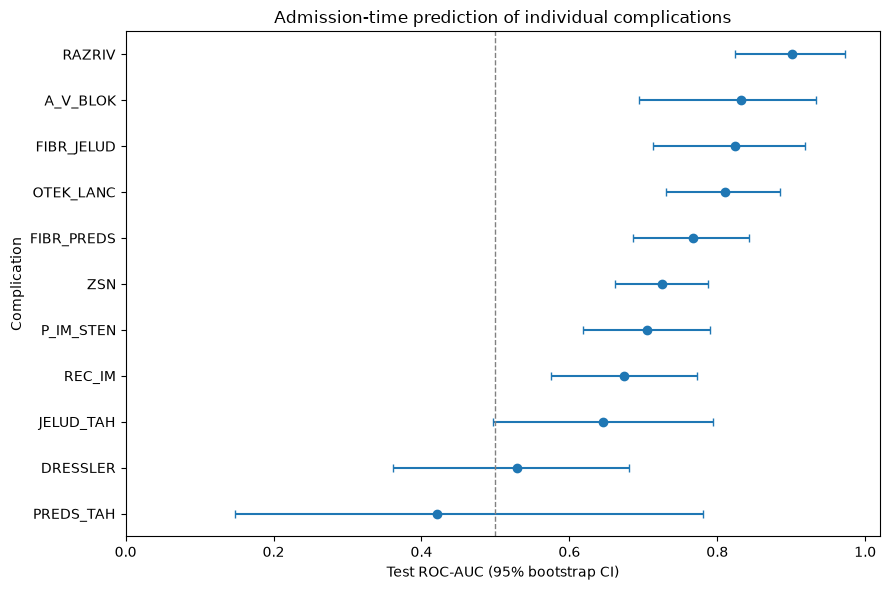

In [36]:
# Sort outcomes from lowest to highest ROC-AUC for the plot
plot_data = final_outcome_results.sort_values("Test ROC-AUC")

auc = plot_data["Test ROC-AUC"].to_numpy()
lower = plot_data["ROC-AUC 95% CI lower"].to_numpy()
upper = plot_data["ROC-AUC 95% CI upper"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 6))

# Points show test ROC-AUC; horizontal bars show bootstrap uncertainty
ax.errorbar(
    auc,
    plot_data["Outcome"],
    xerr=[auc - lower, upper - auc],
    fmt="o",
    capsize=3
)

# AUC = 0.5 represents chance-level discrimination
ax.axvline(
    0.5,
    linestyle="--",
    color="gray",
    linewidth=1
)

ax.set(
    xlabel="Test ROC-AUC (95% bootstrap CI)",
    ylabel="Complication",
    title="Admission-time prediction of individual complications"
)

ax.set_xlim(0, 1.02)

plt.tight_layout()
plt.show()

## 4.6 Part 4 conclusion

Admission-time information can predict some post-MI complications better than others.

RAZRIV (ROC-AUC 0.901), A_V_BLOK (0.833), FIBR_JELUD (0.823) and OTEK_LANC (0.811) showed the strongest test discrimination. Other outcomes performed more moderately, while DRESSLER and PREDS_TAH showed little evidence of useful discrimination.

However, a high ROC-AUC did not always correspond to high average precision, particularly for rare complications. Bootstrap confidence intervals also showed substantial uncertainty when only a few positive test cases were available.
The large differences between training and cross-validation performance indicate that overfitting remains a concern. The models therefore provide evidence of predictive associations within this dataset, but their clinical usefulness has not been established.

**The main finding is that prediction from admission data is possible for several complications, but reliability depends strongly on the specific outcome and the number of positive cases.**


# Part 5: Incremental Predictive Value of Clinical Information During Hospitalization

This part examines whether additional clinical information collected during hospitalization improves prediction of the 11 myocardial infarction complications.

Random-forest models are compared at admission, 24, 48, and 72 hours using the same patients and fixed outcome-specific hyperparameters. Performance is evaluated using ROC-AUC, average precision (AP), and paired bootstrap confidence intervals.

An exploratory analysis also examines whether engineered temporal features provide additional predictive value.


## 5.1 Temporal predictor structure

The predictor sets are cumulative, increasing from 98 variables at admission to 107 at 72 hours. The following tables show the number of predictors and the variables introduced at each time point.

In [37]:
# Summarize the number of available predictors at each time point
temporal_structure = pd.DataFrame({
    "Time point": ["Admission", "24 hours", "48 hours", "72 hours"],
    "Total predictors": [
        X_admission.shape[1],
        X_24h.shape[1],
        X_48h.shape[1],
        X_72h.shape[1]
    ]
})

# Calculate how many additional predictors become available
temporal_structure["New predictors"] = (
    temporal_structure["Total predictors"]
    .diff()
    .fillna(temporal_structure["Total predictors"].iloc[0])
    .astype(int)
)

display(temporal_structure)

,Time point,Total predictors,New predictors
0,Admission,98,98
1,24 hours,101,3
2,48 hours,104,3
3,72 hours,107,3


In [38]:
# Identify the new predictor columns introduced at each time point
new_24h = sorted(set(X_24h.columns) - set(X_admission.columns))
new_48h = sorted(set(X_48h.columns) - set(X_24h.columns))
new_72h = sorted(set(X_72h.columns) - set(X_48h.columns))

new_predictors = pd.DataFrame({
    "24 hours": pd.Series(new_24h),
    "48 hours": pd.Series(new_48h),
    "72 hours": pd.Series(new_72h)
})

display(new_predictors)

,24 hours,48 hours,72 hours
0,NA_R_1_n,NA_R_2_n,NA_R_3_n
1,NOT_NA_1_n,NOT_NA_2_n,NOT_NA_3_n
2,R_AB_1_n,R_AB_2_n,R_AB_3_n


## 5.2 Complication-specific models across time points

For each complication, a random forest is refitted at all four time points. The hyperparameters selected in Part 4 and the training/test split remain unchanged, allowing a direct comparison of predictive performance.

In [39]:
time_order = ["Admission", "24 hours", "48 hours", "72 hours"]

temporal_models = {}
temporal_predictions = {}
temporal_results_list = []

# Train and evaluate each complication-specific model at all four time points
for outcome in binary_outcomes:
    print(f"Processing {outcome}...")

    # Reuse the hyperparameters selected in Part 4
    best_params = outcome_searches[outcome].best_params_
    rf_params = {
        key.replace("model__", ""): value
        for key, value in best_params.items()
        if key.startswith("model__")
    }

    temporal_models[outcome] = {}
    temporal_predictions[outcome] = {}

    for time in time_order:
        # Fit preprocessing and the random forest on training patients only
        model = Pipeline([
            ("preprocessor", clone(preprocessors[time])),
            ("model", RandomForestClassifier(
                **rf_params,
                random_state=42,
                n_jobs=-1
            ))
        ])

        model.fit(X_train[time], Y_train[outcome])
        y_prob = model.predict_proba(X_test[time])[:, 1]

        # Store models, predictions and held-out performance.
        temporal_models[outcome][time] = model
        temporal_predictions[outcome][time] = y_prob

        temporal_results_list.append({
            "Outcome": outcome,
            "Time": time,
            "Test ROC-AUC": roc_auc_score(Y_test[outcome], y_prob),
            "Test AP": average_precision_score(Y_test[outcome], y_prob)
        })

temporal_results = pd.DataFrame(temporal_results_list)
display(temporal_results.round(3))


Processing FIBR_PREDS...
Processing PREDS_TAH...
Processing JELUD_TAH...
Processing FIBR_JELUD...
Processing A_V_BLOK...
Processing OTEK_LANC...
Processing RAZRIV...
Processing DRESSLER...
Processing ZSN...
Processing REC_IM...
Processing P_IM_STEN...


,Outcome,Time,Test ROC-AUC,Test AP
0,FIBR_PREDS,Admission,0.768,0.275
1,FIBR_PREDS,24 hours,0.786,0.258
2,FIBR_PREDS,48 hours,0.791,0.265
3,FIBR_PREDS,72 hours,0.759,0.255
4,PREDS_TAH,Admission,0.420,0.013
5,PREDS_TAH,24 hours,0.426,0.013
6,PREDS_TAH,48 hours,0.410,0.013
7,PREDS_TAH,72 hours,0.359,0.011
8,JELUD_TAH,Admission,0.645,0.047
9,JELUD_TAH,24 hours,0.658,0.047


## 5.3 Performance comparison across time points

ROC-AUC and average precision (AP) are compared across time points. Changes are calculated relative to admission to assess whether additional clinical information improves prediction.

In [40]:
# Compare test ROC-AUC for each complication across time points
auc_by_time = (
    temporal_results
    .pivot(index="Outcome", columns="Time", values="Test ROC-AUC")
    [time_order]
)

display(auc_by_time.round(3))


Time,Admission,24 hours,48 hours,72 hours
Outcome,,,,
A_V_BLOK,0.833,0.839,0.846,0.832
DRESSLER,0.529,0.558,0.550,0.518
FIBR_JELUD,0.823,0.849,0.864,0.860
FIBR_PREDS,0.768,0.786,0.791,0.759
JELUD_TAH,0.645,0.658,0.618,0.642
OTEK_LANC,0.811,0.797,0.815,0.837
PREDS_TAH,0.420,0.426,0.410,0.359
P_IM_STEN,0.705,0.729,0.730,0.708
RAZRIV,0.901,0.866,0.859,0.836


In [41]:
# Calculate the change in ROC-AUC relative to admission
auc_change = pd.DataFrame(index=auc_by_time.index)
auc_change["Admission ROC-AUC"] = auc_by_time["Admission"]

for time in ["24 hours", "48 hours", "72 hours"]:
    auc_change[f"Δ {time}"] = (
        auc_by_time[time] - auc_by_time["Admission"]
    )

display(auc_change.round(3))


,Admission ROC-AUC,Δ 24 hours,Δ 48 hours,Δ 72 hours
Outcome,,,,
A_V_BLOK,0.833,0.007,0.013,-0.000
DRESSLER,0.529,0.029,0.021,-0.011
FIBR_JELUD,0.823,0.026,0.040,0.036
FIBR_PREDS,0.768,0.019,0.023,-0.008
JELUD_TAH,0.645,0.013,-0.027,-0.003
OTEK_LANC,0.811,-0.014,0.005,0.027
PREDS_TAH,0.420,0.006,-0.010,-0.061
P_IM_STEN,0.705,0.024,0.025,0.003
RAZRIV,0.901,-0.036,-0.042,-0.065


In [42]:
# Compare average precision and its change relative to admission
ap_by_time = (
    temporal_results
    .pivot(index="Outcome", columns="Time", values="Test AP")
    [time_order]
)

ap_change = pd.DataFrame(index=ap_by_time.index)
ap_change["Admission AP"] = ap_by_time["Admission"]

for time in ["24 hours", "48 hours", "72 hours"]:
    ap_change[f"Δ {time}"] = (
        ap_by_time[time] - ap_by_time["Admission"]
    )

display(ap_change.round(3))


,Admission AP,Δ 24 hours,Δ 48 hours,Δ 72 hours
Outcome,,,,
A_V_BLOK,0.176,0.042,0.051,0.056
DRESSLER,0.044,0.009,0.005,-0.000
FIBR_JELUD,0.106,0.017,0.038,0.040
FIBR_PREDS,0.275,-0.017,-0.010,-0.020
JELUD_TAH,0.047,0.001,-0.006,-0.003
OTEK_LANC,0.330,-0.009,0.006,0.006
PREDS_TAH,0.013,0.000,-0.000,-0.002
P_IM_STEN,0.282,-0.001,0.023,0.002
RAZRIV,0.319,0.054,0.061,0.055



## 5.4 Predictive performance across time points

The following figure illustrates how test ROC-AUC changes across the four predictor-availability time points. Each line represents a separate complication.


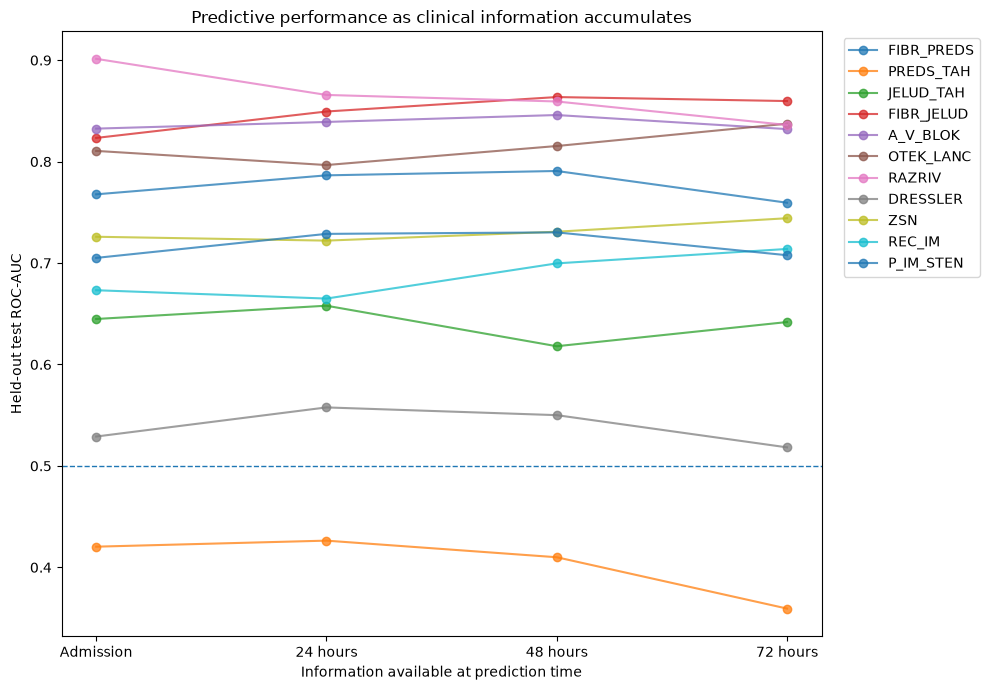

In [43]:
# Plot ROC-AUC trajectories for all 11 complications
plt.figure(figsize=(10, 7))

for outcome in binary_outcomes:
    values = [
        auc_by_time.loc[outcome, time]
        for time in time_order
    ]

    plt.plot(
        time_order,
        values,
        marker="o",
        alpha=0.75,
        label=outcome
    )

# ROC-AUC = 0.5 indicates chance-level discrimination
plt.axhline(0.5, linestyle="--", linewidth=1)

plt.xlabel("Information available at prediction time")
plt.ylabel("Held-out test ROC-AUC")
plt.title("Predictive performance as clinical information accumulates")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 5.5 Uncertainty in predictive improvement

Paired bootstrap resampling (2,000 iterations) estimates 95% confidence intervals for ROC-AUC changes relative to admission. The same test patients are resampled for both time points, preserving the paired comparison.

In [44]:
def paired_bootstrap_auc_difference(
    y_true,
    prob_baseline,
    prob_later,
    n_bootstraps=2000,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    y_true = np.asarray(y_true)
    prob_baseline = np.asarray(prob_baseline)
    prob_later = np.asarray(prob_later)

    # Observed difference: later ROC-AUC minus admission ROC-AUC
    point_estimate = (
        roc_auc_score(y_true, prob_later)
        - roc_auc_score(y_true, prob_baseline)
    )

    differences = []

    # Resample the same patient indices for both predictions
    for _ in range(n_bootstraps):
        idx = rng.choice(
            len(y_true),
            size=len(y_true),
            replace=True
        )

        y_boot = y_true[idx]

        # ROC-AUC requires both outcome classes
        if len(np.unique(y_boot)) < 2:
            continue

        auc_baseline = roc_auc_score(
            y_boot, prob_baseline[idx]
        )
        auc_later = roc_auc_score(
            y_boot, prob_later[idx]
        )

        differences.append(auc_later - auc_baseline)

    differences = np.asarray(differences)

    # Percentile-based 95% confidence interval
    return (
        point_estimate,
        np.percentile(differences, 2.5),
        np.percentile(differences, 97.5)
    )

In [45]:
incremental_results = []

# Estimate paired ROC-AUC differences for each complication and later time point
for outcome in binary_outcomes:
    y_true = Y_test[outcome].to_numpy()

    admission_prob = np.asarray(
        temporal_predictions[outcome]["Admission"]
    )

    for time in ["24 hours", "48 hours", "72 hours"]:
        later_prob = np.asarray(
            temporal_predictions[outcome][time]
        )

        difference, lower, upper = paired_bootstrap_auc_difference(
            y_true,
            admission_prob,
            later_prob,
            n_bootstraps=2000,
            random_state=42
        )

        incremental_results.append({
            "Outcome": outcome,
            "Comparison": f"{time} vs Admission",
            "Δ ROC-AUC": difference,
            "95% CI lower": lower,
            "95% CI upper": upper
        })

incremental_results = pd.DataFrame(incremental_results)
display(incremental_results.round(3))

,Outcome,Comparison,Δ ROC-AUC,95% CI lower,95% CI upper
0,FIBR_PREDS,24 hours vs Admission,0.019,-0.023,0.066
1,FIBR_PREDS,48 hours vs Admission,0.023,-0.017,0.067
2,FIBR_PREDS,72 hours vs Admission,-0.008,-0.065,0.050
3,PREDS_TAH,24 hours vs Admission,0.006,-0.021,0.032
4,PREDS_TAH,48 hours vs Admission,-0.010,-0.055,0.036
5,PREDS_TAH,72 hours vs Admission,-0.061,-0.095,-0.028
6,JELUD_TAH,24 hours vs Admission,0.013,-0.038,0.063
7,JELUD_TAH,48 hours vs Admission,-0.027,-0.067,0.012
8,JELUD_TAH,72 hours vs Admission,-0.003,-0.048,0.044
9,FIBR_JELUD,24 hours vs Admission,0.026,0.006,0.048


## 5.6 Incremental predictive value at 72 hours

The forest plot summarizes the difference in test ROC-AUC between admission and 72 hours, including paired bootstrap 95% confidence intervals.

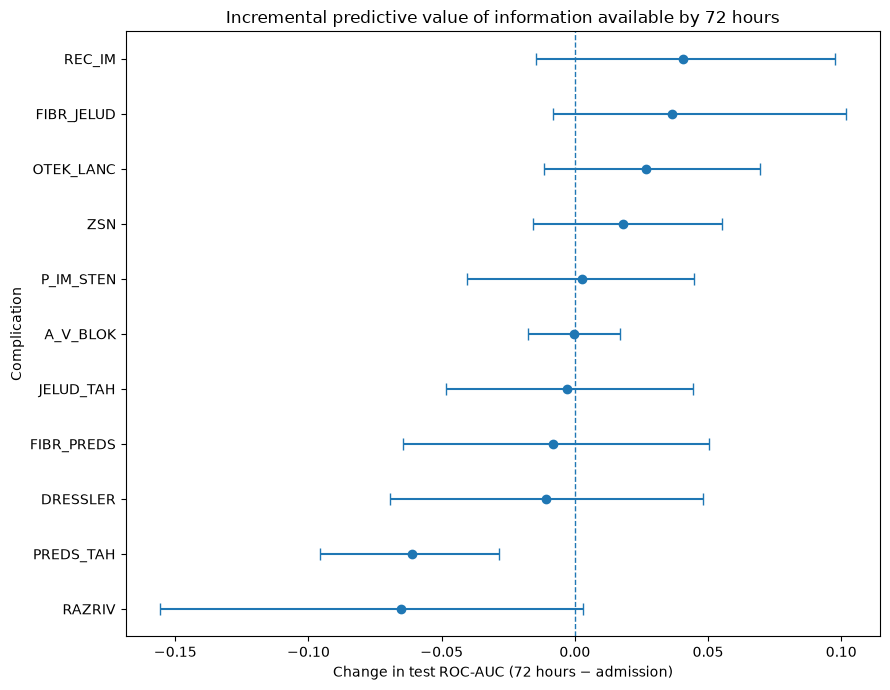

In [46]:
# Select the 72-hour comparisons and sort by ROC-AUC change
plot_data = incremental_results[
    incremental_results["Comparison"] == "72 hours vs Admission"
].copy()

plot_data = plot_data.sort_values("Δ ROC-AUC")
y_pos = np.arange(len(plot_data))

# Calculate asymmetric errornbar lengths from confidence limits
lower_error = (
    plot_data["Δ ROC-AUC"] - plot_data["95% CI lower"]
)
upper_error = (
    plot_data["95% CI upper"] - plot_data["Δ ROC-AUC"]
)

plt.figure(figsize=(9, 7))

plt.errorbar(
    plot_data["Δ ROC-AUC"],
    y_pos,
    xerr=[lower_error, upper_error],
    fmt="o",
    capsize=4
)

# Zero indicates no difference from admission performance
plt.axvline(0, linestyle="--", linewidth=1)

plt.yticks(y_pos, plot_data["Outcome"])
plt.xlabel("Change in test ROC-AUC (72 hours − admission)")
plt.ylabel("Complication")
plt.title("Incremental predictive value of information available by 72 hours")

plt.tight_layout()
plt.show()

In [47]:
# Classify changes according to whether the confidence interval excludes zero
summary_72h = incremental_results[
    incremental_results["Comparison"] == "72 hours vs Admission"
].copy()

summary_72h["Interpretation"] = np.select(
    [
        summary_72h["95% CI lower"] > 0,
        summary_72h["95% CI upper"] < 0
    ],
    [
        "Evidence of increase",
        "Evidence of decrease"
    ],
    default="Uncertain change"
)

summary_72h = (
    summary_72h[
        [
            "Outcome",
            "Δ ROC-AUC",
            "95% CI lower",
            "95% CI upper",
            "Interpretation"
        ]
    ]
    .sort_values("Δ ROC-AUC", ascending=False)
)

display(summary_72h.round(3))

,Outcome,Δ ROC-AUC,95% CI lower,95% CI upper,Interpretation
29,REC_IM,0.041,-0.015,0.098,Uncertain change
11,FIBR_JELUD,0.036,-0.008,0.102,Uncertain change
17,OTEK_LANC,0.027,-0.011,0.069,Uncertain change
26,ZSN,0.018,-0.016,0.055,Uncertain change
32,P_IM_STEN,0.003,-0.041,0.045,Uncertain change
14,A_V_BLOK,-0.000,-0.017,0.017,Uncertain change
8,JELUD_TAH,-0.003,-0.048,0.044,Uncertain change
2,FIBR_PREDS,-0.008,-0.065,0.050,Uncertain change
23,DRESSLER,-0.011,-0.069,0.048,Uncertain change
5,PREDS_TAH,-0.061,-0.095,-0.028,Evidence of decrease


## 5.7 Temporal feature engineering

Daily measurements may not fully capture changes during hospitalization. Additional features therefore summarize cumulative observations, the number of observed days, and changes between consecutive measurements.
This supplementary analysis uses only information available at each time point and is exploratory.

In [48]:
def add_temporal_features(X, time):
    X_new = X.copy()

    # Use only days available at the selected prediction time
    available_days = {
        "Admission": 0,
        "24 hours": 1,
        "48 hours": 2,
        "72 hours": 3
    }[time]

    if available_days == 0:
        return X_new

    # Summarize repeated pain-related and treatment measurements
    for prefix in ["NA_R", "NOT_NA", "R_AB"]:
        columns = [
            f"{prefix}_{day}_n"
            for day in range(1, available_days + 1)
        ]

        values = X_new[columns].apply(
            pd.to_numeric, errors="coerce"
        )

        X_new[f"{prefix}_cumulative"] = (
            values.sum(axis=1, min_count=1)
        )

        X_new[f"{prefix}_observed_days"] = (
            values.notna().sum(axis=1)
        )

        # Add the latest day-to-day change when two days are available
        if available_days >= 2:
            current = values.iloc[:, -1]
            previous = values.iloc[:, -2]

            X_new[f"{prefix}_latest_change"] = (
                current - previous
            )

    return X_new


# Construct engineered training predictors for each time point
X_train_engineered = {
    time: add_temporal_features(X_train[time], time)
    for time in time_order
}

# Show how many additional features were created
feature_summary = pd.DataFrame([
    {
        "Time point": time,
        "Original predictors": X_train[time].shape[1],
        "Engineered predictors": X_train_engineered[time].shape[1],
        "Added features": (
            X_train_engineered[time].shape[1]
            - X_train[time].shape[1]
        )
    }
    for time in time_order
])

display(feature_summary)

,Time point,Original predictors,Engineered predictors,Added features
0,Admission,98,98,0
1,24 hours,101,107,6
2,48 hours,104,113,9
3,72 hours,107,116,9


## 5.8 Evaluation of engineered temporal features

Original and engineered predictors are compared using stratified five-fold cross-validation within the training cohort for ZSN, OTEK_LANC, and REC_IM. The same random-forest hyperparameters are used for both representations.

In [49]:
def engineered_preprocessor(X, time):
    original_columns = list(X_train[time].columns)

    # Identify features added by temporal engineering
    extra_columns = [
        column for column in X.columns
        if column not in original_columns
    ]

    if not extra_columns:
        return clone(preprocessors[time])

    # Preprocess original and engineered features separately
    return ColumnTransformer([
        (
            "original",
            clone(preprocessors[time]),
            original_columns
        ),
        (
            "engineered",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            extra_columns
        )
    ])

In [50]:
temporal_outcomes = ["ZSN", "OTEK_LANC", "REC_IM"]

cv_temporal = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

engineering_cv_results = []

# Compare original and engineered predictors using training-only CV
for outcome in temporal_outcomes:
    best_params = outcome_searches[outcome].best_params_

    rf_params = {
        key.replace("model__", ""): value
        for key, value in best_params.items()
        if key.startswith("model__")
    }

    for time in time_order:
        for representation, X_data in [
            ("Original", X_train[time]),
            ("Engineered", X_train_engineered[time])
        ]:
            if representation == "Original":
                preprocessor = clone(preprocessors[time])
            else:
                preprocessor = engineered_preprocessor(X_data, time)

            model = Pipeline([
                ("preprocessor", preprocessor),
                ("model", RandomForestClassifier(
                    **rf_params,
                    random_state=42,
                    n_jobs=1
                ))
            ])

            # Preprocessing is fitted separately within each CV fold
            scores = cross_val_score(
                model,
                X_data,
                Y_train[outcome],
                scoring="roc_auc",
                cv=cv_temporal,
                n_jobs=-1
            )

            engineering_cv_results.append({
                "Outcome": outcome,
                "Time": time,
                "Representation": representation,
                "CV ROC-AUC": scores.mean(),
                "CV SD": scores.std()
            })

engineering_cv_results = pd.DataFrame(engineering_cv_results)
display(engineering_cv_results.round(3))

,Outcome,Time,Representation,CV ROC-AUC,CV SD
0,ZSN,Admission,Original,0.732,0.020
1,ZSN,Admission,Engineered,0.732,0.020
2,ZSN,24 hours,Original,0.733,0.020
3,ZSN,24 hours,Engineered,0.732,0.019
4,ZSN,48 hours,Original,0.739,0.016
5,ZSN,48 hours,Engineered,0.761,0.019
6,ZSN,72 hours,Original,0.742,0.015
7,ZSN,72 hours,Engineered,0.769,0.017
8,OTEK_LANC,Admission,Original,0.748,0.025
9,OTEK_LANC,Admission,Engineered,0.748,0.025


In [51]:
# Compare mean CV ROC-AUC for engineered versus original predictors.
engineering_comparison = (
    engineering_cv_results
    .pivot(
        index=["Outcome", "Time"],
        columns="Representation",
        values="CV ROC-AUC"
    )
    .reset_index()
)

engineering_comparison["Difference"] = (
    engineering_comparison["Engineered"]
    - engineering_comparison["Original"]
)

display(engineering_comparison.round(3))

Representation,Outcome,Time,Engineered,Original,Difference
0,OTEK_LANC,24 hours,0.762,0.760,0.003
1,OTEK_LANC,48 hours,0.768,0.762,0.007
2,OTEK_LANC,72 hours,0.763,0.759,0.003
3,OTEK_LANC,Admission,0.748,0.748,0.000
4,REC_IM,24 hours,0.652,0.637,0.015
5,REC_IM,48 hours,0.671,0.659,0.011
6,REC_IM,72 hours,0.689,0.662,0.027
7,REC_IM,Admission,0.643,0.643,0.000
8,ZSN,24 hours,0.732,0.733,-0.002
9,ZSN,48 hours,0.761,0.739,0.022


## 5.9 Conclusion

Additional clinical information during the first 72 hours did not consistently improve prediction. Most changes in test ROC-AUC were small and uncertain, although PREDS_TAH showed a decrease at 72 hours.

Exploratory temporal feature engineering improved cross-validated ROC-AUC for ZSN and REC_IM by 0.027 each, with little improvement for OTEK_LANC (+0.004).

Overall, more clinical measurements do not necessarily improve prediction. How the information is represented may also matter, but these exploratory results require independent validation.

# Part 6: Interpretation of Predictive Information

Parts 4 and 5 examined how well the models predicted complications after myocardial infarction and whether information collected during hospitalization improved performance.

This part looks more closely at what the models learned. The aim is to identify which clinical information contributes most to prediction and whether the additional measurements collected after admission are useful.
Three approaches are used: removing groups of related predictors, measuring the importance of individual admission predictors, and examining predictors added during hospitalization.

## 6.1 Clinical predictor groups

Individual predictors can be difficult to interpret because several variables describe related aspects of a patient's condition. To understand which types of clinical information are most useful, the admission predictors were divided into groups such as cardiovascular history, laboratory measurements, and pain and treatment.

Each group was removed in turn, and the random forest was evaluated again using cross-validation. The difference in AP between the full and reduced models shows how much predictive information was lost when that group was excluded. AP was used because it is informative when complications are relatively uncommon.

The analysis focuses on three complications: heart failure (ZSN), pulmonary edema (OTEK_LANC), and recurrent myocardial infarction (REC_IM). This allows a more detailed comparison without repeating the interpretation for all eleven outcomes.

In [52]:
# Group admission predictors by their clinical meaning
# Group ablation tests their combined contribution to prediction
clinical_groups = {
    "Demographics": [
        "AGE", "SEX"
    ],
    "Cardiovascular history": [
        "INF_ANAM", "STENOK_AN", "FK_STENOK", "IBS_POST",
        "IBS_NASL", "GB", "SIM_GIPERT", "DLIT_AG", "ZSN_A"
    ],
    "Previous rhythm disorders": [
        "nr11", "nr01", "nr02", "nr03", "nr04", "nr07", "nr08",
        "np01", "np04", "np05", "np07", "np08", "np09", "np10"
    ],
    "Other comorbidities": [
        "endocr_01", "endocr_02", "endocr_03",
        "zab_leg_01", "zab_leg_02", "zab_leg_03",
        "zab_leg_04", "zab_leg_06"
    ],
    "Admission clinical status": [
        "S_AD_KBRIG", "D_AD_KBRIG", "S_AD_ORIT", "D_AD_ORIT",
        "O_L_POST", "K_SH_POST", "MP_TP_POST", "SVT_POST",
        "GT_POST", "FIB_G_POST", "TIME_B_S"
    ],
    "Infarction characteristics": [
        "ant_im", "lat_im", "inf_im", "post_im", "IM_PG_P"
    ],
    "Laboratory": [
        "GIPO_K", "K_BLOOD", "GIPER_Na", "Na_BLOOD",
        "ALT_BLOOD", "AST_BLOOD", "KFK_BLOOD", "L_BLOOD", "ROE"
    ],
    "Fibrinolytic therapy": [
        "fibr_ter_01", "fibr_ter_02", "fibr_ter_03",
        "fibr_ter_05", "fibr_ter_06", "fibr_ter_07",
        "fibr_ter_08"
    ],
    "Pain and treatment": [
        "R_AB_1_n", "R_AB_2_n", "R_AB_3_n",
        "NA_KB", "NOT_NA_KB", "LID_KB", "NITR_S",
        "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",
        "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n",
        "LID_S_n", "B_BLOK_S_n", "ANT_CA_S_n",
        "GEPAR_S_n", "ASP_S_n", "TIKL_S_n", "TRENT_S_n"
    ],
    "Admission ECG": [
        col for col in X_admission_train.columns
        if col.startswith(("ritm_ecg", "n_r_ecg", "n_p_ecg"))
    ]
}

# Exclude variables removed during preprocessing or unavailable at admission. Empty clinical groups are also removed
clinical_groups = {
    group: [col for col in cols if col in X_admission_train.columns]
    for group, cols in clinical_groups.items()
}
clinical_groups = {
    group: cols
    for group, cols in clinical_groups.items()
    if cols
}

# Check that no predictor is assigned to more than one group
grouped = [
    col
    for cols in clinical_groups.values()
    for col in cols
]
assert len(grouped) == len(set(grouped)), "Overlapping clinical groups."

# Include any admission predictors not covered by the predefined groups
# This ensures the complete admission dataset is represented
remaining = [
    col for col in X_admission_train.columns
    if col not in grouped
]
if remaining:
    clinical_groups["Other admission predictors"] = remaining

# Focus the interpretation on three different complications
interpretation_outcomes = ["ZSN", "OTEK_LANC", "REC_IM"]

# Three-fold stratified CV preserves approximately the same
# outcome prevalence in each fold
cv_interpretation = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)


def make_interpretation_model(outcome, X_data):
    """
    Build an unfitted random-forest pipeline using the
    outcome-specific hyperparameters selected in Part 4.
    """

    # Reuse the selected hyperparameters for consistency with the earlier complication-specific models
    best_params = outcome_searches[outcome].best_params_

    rf_params = {
        key.replace("model__", ""): value
        for key, value in best_params.items()
        if key.startswith("model__")
    }

    rf_params.update(random_state=42, n_jobs=1)

    # Preprocessing remains inside the pipeline so that it is fitted separately within each training fold
    return Pipeline([
        ("preprocessor", create_preprocessor(X_data)),
        ("model", RandomForestClassifier(**rf_params))
    ])


print(f"Clinical groups: {len(clinical_groups)}")
print(f"Admission predictors: {X_admission_train.shape[1]}")


Clinical groups: 10
Admission predictors: 98


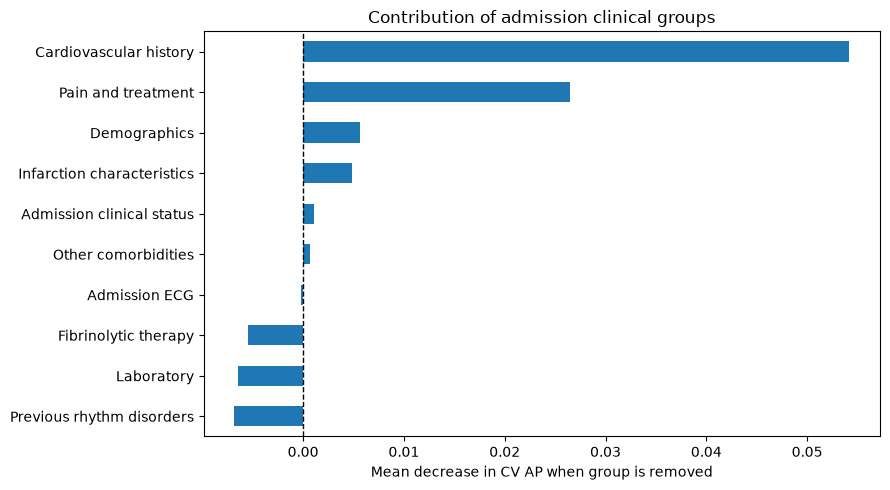

In [53]:
# Record the change in average precision when each group is removed
ablation_results = []

for outcome in interpretation_outcomes:
    y = Y_train[outcome]

    # Calculate reference performance using all admission predictors
    full_ap = cross_val_score(
        make_interpretation_model(outcome, X_admission_train),
        X_admission_train,
        y,
        cv=cv_interpretation,
        scoring="average_precision",
        n_jobs=-1
    ).mean()

    # Remove one clinical group at a time and refit the model
    # The same CV strategy allows comparison with the full model
    for group, variables in clinical_groups.items():
        X_reduced = X_admission_train.drop(columns=variables)

        reduced_ap = cross_val_score(
            make_interpretation_model(outcome, X_reduced),
            X_reduced,
            y,
            cv=cv_interpretation,
            scoring="average_precision",
            n_jobs=-1
        ).mean()

        # Positive contribution: performance decreased without the group
        # Negative contribution: performance improved without the group
        ablation_results.append({
            "Outcome": outcome,
            "Clinical group": group,
            "AP contribution": full_ap - reduced_ap
        })

clinical_ablation_df = pd.DataFrame(ablation_results)

# Average group contributions across the three complications
domain_summary = (
    clinical_ablation_df
    .groupby("Clinical group")["AP contribution"]
    .mean()
    .sort_values()
)

# Plot the mean contribution of each clinical group
fig, ax = plt.subplots(figsize=(9, 5))

domain_summary.plot.barh(ax=ax)

# Zero means that removing the group did not change average precision
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Mean decrease in CV AP when group is removed")
ax.set_ylabel("")
ax.set_title("Contribution of admission clinical groups")

plt.tight_layout()
plt.show()


## 6.2 Most important individual admission predictors

Group ablation identifies which types of clinical information are useful, but it does not show which individual variables contribute most. For this reason, permutation importance was used as a second approach.

For each complication, the training cohort was divided into a fitting subset and a separate validation subset. After fitting the random forest, each admission predictor was shuffled five times while the other variables remained unchanged. The decrease in validation AP was used to estimate its importance.

Unlike group ablation, permutation importance does not retrain the model. It measures how much the fitted model relies on a particular variable. The independent test cohort was not used in this analysis.

,Outcome,Variable,AP importance
0,OTEK_LANC,NITR_S,0.0856
1,OTEK_LANC,endocr_01,0.0126
2,OTEK_LANC,Na_BLOOD,0.0095
3,OTEK_LANC,O_L_POST,0.0078
4,OTEK_LANC,nr01,0.0061
5,REC_IM,STENOK_AN,0.0066
6,REC_IM,D_AD_ORIT,0.0044
7,REC_IM,ANT_CA_S_n,0.0031
8,REC_IM,AGE,0.0029
9,REC_IM,LID_KB,0.0028


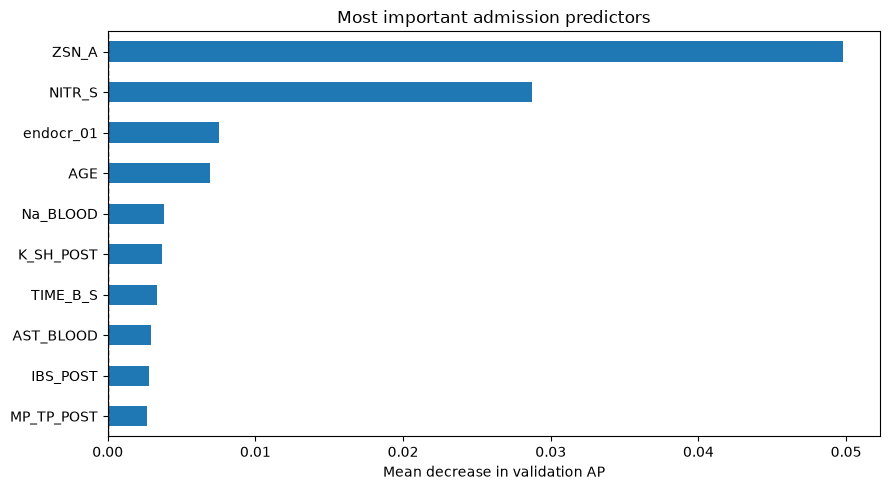

In [54]:
# Store individual predictor importance for the three complications
admission_importance_rows = []

for outcome in interpretation_outcomes:
    y = Y_train[outcome]

    # Use a stratified 75/25 split within the training cohort
    # The validation subset is used to measure importance on patients who were not used to fit this model
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_admission_train,
        y,
        test_size=0.25,
        stratify=y,
        random_state=42
    )

    # Fit the outcome-specific random forest on the fitting subset
    model = make_interpretation_model(outcome, X_fit)
    model.fit(X_fit, y_fit)

    # Shuffle each original predictor five times and measure the decrease in validation AP. The model is not retrained
    # Using the full pipeline allows permutation of original clinical variables rather than one-hot encoded columns
    importance = permutation_importance(
        model,
        X_val,
        y_val,
        scoring="average_precision",
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    # Store the mean AP decrease for each original predictor
    for variable, score in zip(
        X_val.columns,
        importance.importances_mean
    ):
        admission_importance_rows.append({
            "Outcome": outcome,
            "Variable": variable,
            "AP importance": score
        })

admission_importance = pd.DataFrame(admission_importance_rows)

# Identify the five strongest predictors for each complication
top_by_outcome = (
    admission_importance
    .sort_values("AP importance", ascending=False)
    .groupby("Outcome")
    .head(5)
    .sort_values(
        ["Outcome", "AP importance"],
        ascending=[True, False]
    )
)

display(top_by_outcome.reset_index(drop=True).round(4))

# Average predictor importance across the three outcomes
# This provides an overall comparison, although individual complications may depend on different predictors
predictor_summary = (
    admission_importance
    .groupby("Variable")["AP importance"]
    .mean()
    .sort_values(ascending=False)
)

# Plot the ten predictors with the highest mean importance
fig, ax = plt.subplots(figsize=(9, 5))

predictor_summary.head(10).sort_values().plot.barh(ax=ax)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Mean decrease in validation AP")
ax.set_ylabel("")
ax.set_title("Most important admission predictors")

plt.tight_layout()
plt.show()


## 6.3 Importance of additional information at 72 hours

Part 5 showed that including later clinical measurements did not consistently improve prediction. To understand this result better, I examined the nine predictors available at 72 hours but not at admission.
Permutation importance was calculated using the 72-hour models. Each additional predictor was shuffled five times, and the resulting change in validation AP was measured.

This analysis helps identify whether individual later measurements contribute useful information, even when adding all nine predictors does not improve overall performance. The analysis again uses a validation subset of the training cohort rather than the independent test set.

Additional predictors: 9
['R_AB_1_n', 'R_AB_2_n', 'R_AB_3_n', 'NA_R_1_n', 'NA_R_2_n', 'NA_R_3_n', 'NOT_NA_1_n', 'NOT_NA_2_n', 'NOT_NA_3_n']


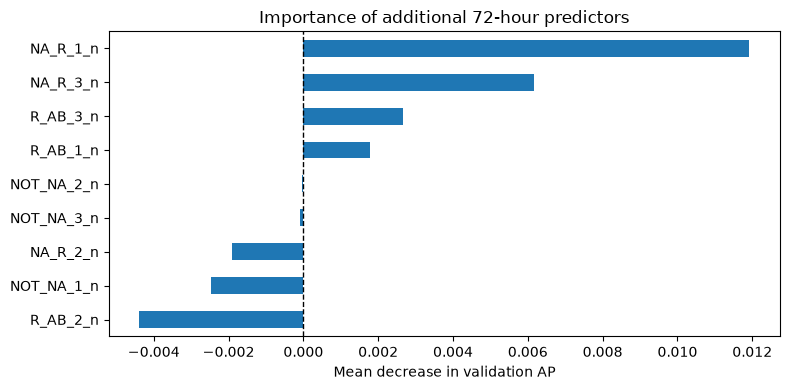

In [55]:
# Use the training predictors available at 72 hours
X_72h_train = X_train["72 hours"]

# Identify variables introduced after admission
# These are the nine additional predictors examined in Part 5
dynamic_variables = [
    col for col in X_72h_train.columns
    if col not in X_admission_train.columns
]

print(f"Additional predictors: {len(dynamic_variables)}")
print(dynamic_variables)

# Store the importance of each additional predictor
dynamic_importance_rows = []

for outcome in interpretation_outcomes:
    y = Y_train[outcome]

    # Separate fitting and validation patients
    # Stratification helps preserve the complication prevalence
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_72h_train,
        y,
        test_size=0.25,
        stratify=y,
        random_state=42
    )

    # Fit a 72-hour random forest using the outcome-specific hyperparameters selected in Part 4
    model = make_interpretation_model(outcome, X_fit)
    model.fit(X_fit, y_fit)

    # Calculate validation AP before any predictors are shuffled
    # This provides the reference for measuring importance
    baseline_ap = average_precision_score(
        y_val,
        model.predict_proba(X_val)[:, 1]
    )

    rng = np.random.default_rng(42)

    # Shuffle only predictors introduced after admission
    # All other variables remain unchanged
    for variable in dynamic_variables:
        decreases = []

        for _ in range(5):
            X_permuted = X_val.copy()

            # Randomly rearrange this predictor across patients,disrupting its relationship with the outcome
            X_permuted[variable] = rng.permutation(
                X_val[variable].to_numpy()
            )

            # Evaluate the same fitted model on the modified data
            permuted_ap = average_precision_score(
                y_val,
                model.predict_proba(X_permuted)[:, 1]
            )

            # Positive values mean that shuffling reduced AP
            decreases.append(baseline_ap - permuted_ap)

        # Average importance over five random permutations
        dynamic_importance_rows.append({
            "Outcome": outcome,
            "Variable": variable,
            "AP importance": np.mean(decreases)
        })

dynamic_importance = pd.DataFrame(dynamic_importance_rows)

# Average importance across the three selected complications
dynamic_summary = (
    dynamic_importance
    .groupby("Variable")["AP importance"]
    .mean()
    .sort_values()
)

# Plot the contribution of the additional 72-hour predictors
fig, ax = plt.subplots(figsize=(8, 4))

dynamic_summary.plot.barh(ax=ax)

# Zero indicates no measured change in validation AP
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Mean decrease in validation AP")
ax.set_ylabel("")
ax.set_title("Importance of additional 72-hour predictors")

plt.tight_layout()
plt.show()


## 6.4 Conclusion

Cardiovascular history and pain and treatment information were the most useful admission predictor groups. At the individual level, previous heart failure and nitrate treatment were among the strongest predictors.

The additional 72-hour measurements showed mixed importance. Overall, the results suggest that the type of clinical information available matters more than simply increasing the number of predictors.

# Part 7: Branching Clinical Trajectories and Complication Profiles

Previous sections investigated whether post-MI complications could
be predicted and how predictive information changed during
hospitalization.

This section investigates whether patients occupy different
clinical pathways and whether these pathways are associated with
different complication profiles.

The analysis is inspired by Golovenkin et al. (2020), who used
elastic principal trees to reconstruct branching clinical
trajectories from observational patient data.

Here, a principal tree is constructed using clinical predictors
available by 72 hours. The eleven complication outcomes are
excluded from tree construction and examined afterwards.

The resulting branches represent inferred clinical pathways,
not directly observed longitudinal patient trajectories.

## 7.1 Preparing clinical data

The clinical representation combines admission characteristics
with additional information recorded during hospitalization.

Categorical variables are one-hot encoded, numerical variables
are imputed and standardized, and principal component analysis
(PCA) reduces dimensionality before fitting the principal tree.

All preprocessing is fitted on the training cohort only.
Complication outcomes are excluded to avoid outcome leakage.

PCA is used to obtain a compact representation suitable for
elastic principal-tree reconstruction.

In [56]:
outcomes = [
    "FIBR_PREDS", "PREDS_TAH", "JELUD_TAH",
    "FIBR_JELUD", "A_V_BLOK", "OTEK_LANC",
    "RAZRIV", "DRESSLER", "ZSN",
    "REC_IM", "P_IM_STEN"
]

# Original clinical variables available by 72 hours.
X7_train = X_72h_train.copy()
X7_test = X_72h_test.copy()

# Ensure no outcome variables enter the tree.
X7_train = X7_train.drop(columns=outcomes, errors="ignore")
X7_test = X7_test[X7_train.columns]

# Distinguish continuous measurements from coded categories.
continuous_candidates = [
    "AGE", "S_AD_ORIT", "D_AD_ORIT",
    "K_BLOOD", "Na_BLOOD", "ALT_BLOOD",
    "AST_BLOOD", "L_BLOOD", "ROE"
]

continuous_cols = [
    c for c in continuous_candidates
    if c in X7_train.columns
]

categorical_cols = [
    c for c in X7_train.columns
    if c not in continuous_cols
]

# Missing-value imputation and type-specific transformations.
clinical_preprocessor = ColumnTransformer([
    ("continuous", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), continuous_cols),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), categorical_cols)
])

Z_train = clinical_preprocessor.fit_transform(X7_train)
Z_test = clinical_preprocessor.transform(X7_test)

# Reduce dimensionality while retaining most variation.
pca = PCA(n_components=0.85, svd_solver="full")
P_train = pca.fit_transform(Z_train)
P_test = pca.transform(Z_test)

# Limit tree fitting to the leading components.
n_components = min(10, P_train.shape[1])

P_train = P_train[:, :n_components]
P_test = P_test[:, :n_components]

print("Training patients:", len(P_train))
print("Test patients:", len(P_test))
print("PCA components used:", n_components)
print(
    "Variance explained by retained components:",
    round(
        pca.explained_variance_ratio_[:n_components].sum(),
        3
    )
)

Training patients: 1360
Test patients: 340
PCA components used: 10
Variance explained by retained components: 0.461


## 7.2 Reconstructing the principal tree

An elastic principal tree is fitted to the PCA representation
of the training patients using ElPiGraph.

Unlike K-means, the model connects representative clinical states
through a branching graph. The tree structure is determined by
the distribution of patients in the clinical feature space.

Graph nodes represent fitted clinical states, while edges
connect neighboring states.

The number of graph nodes controls the resolution of the
representation; it does not directly determine the number
of clinical pathways.

Principal-tree nodes: 30
Principal-tree edges: 29
Branching points: 2
Terminal nodes: 18


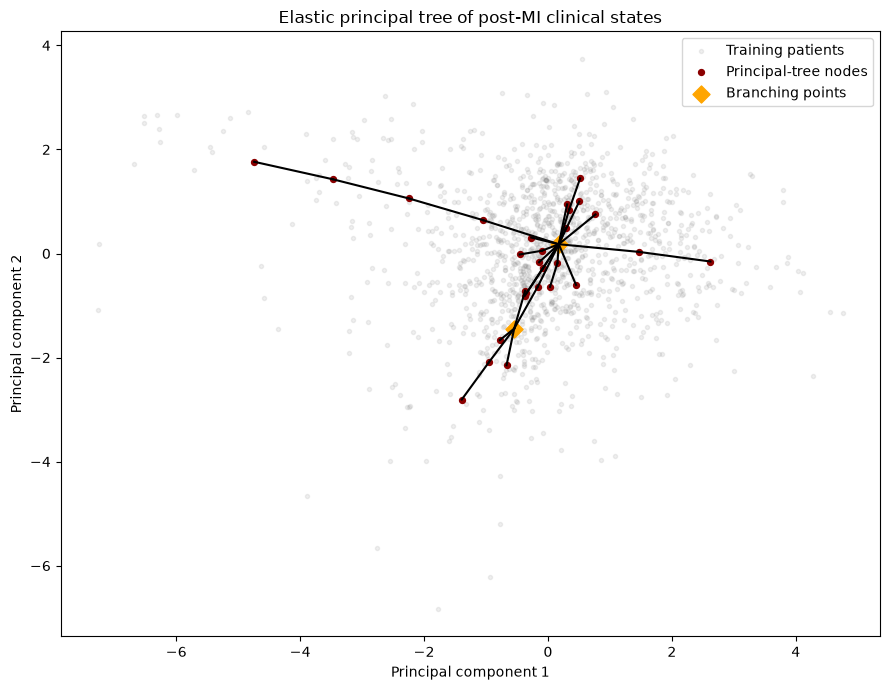

In [57]:
# Fit the principal tree to training patients only.
principal_tree = elpigraph.computeElasticPrincipalTree(
    P_train,
    NumNodes=30,
    Lambda=0.01,
    Mu=0.1,
    Do_PCA=False,
    n_cores=1,
    verbose=False
)[0]

nodes = principal_tree["NodePositions"]
edges = np.asarray(
    principal_tree["Edges"][0],
    dtype=int
)

# Build a graph representing the principal tree.
G = nx.Graph()
G.add_nodes_from(range(len(nodes)))

for a, b in edges:
    distance = np.linalg.norm(nodes[a] - nodes[b])
    G.add_edge(int(a), int(b), weight=float(distance))

print("Principal-tree nodes:", len(nodes))
print("Principal-tree edges:", len(edges))
print(
    "Branching points:",
    sum(degree >= 3 for _, degree in G.degree())
)
print(
    "Terminal nodes:",
    sum(degree == 1 for _, degree in G.degree())
)

# Display the tree in the first two PCA dimensions.
fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    P_train[:, 0], P_train[:, 1],
    s=9, alpha=0.12, color="grey",
    label="Training patients"
)

for a, b in edges:
    ax.plot(
        nodes[[a, b], 0],
        nodes[[a, b], 1],
        color="black",
        linewidth=1.5
    )

ax.scatter(
    nodes[:, 0], nodes[:, 1],
    s=18, color="darkred",
    label="Principal-tree nodes"
)

branch_nodes = [
    n for n, degree in G.degree()
    if degree >= 3
]

if branch_nodes:
    ax.scatter(
        nodes[branch_nodes, 0],
        nodes[branch_nodes, 1],
        s=75, marker="D",
        color="orange",
        label="Branching points"
    )

ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title("Elastic principal tree of post-MI clinical states")
ax.legend()
plt.tight_layout()
plt.show()

## 7.3 Identifying clinical pathways and pseudo-time

The principal tree is divided into non-branching segments.
Each segment represents a local clinical pathway.

Patients are assigned to the nearest fitted graph node and
then to its corresponding segment. Branching-point patients
are assigned to the nearest adjacent segment.

Pseudo-time is defined as the distance along the fitted graph
from a central reference node.

This pseudo-time represents position within the reconstructed
clinical structure. It is not measured hospitalization time
and does not establish the direction of disease progression.

In [58]:
# Identify branching nodes and non-branching segments.
branch_nodes = {
    n for n, degree in G.degree()
    if degree >= 3
}

G_segments = G.copy()
G_segments.remove_nodes_from(branch_nodes)

segments = [
    sorted(component)
    for component in nx.connected_components(G_segments)
]

# Keep only segments containing at least one graph edge.
segments = [
    component for component in segments
    if len(component) >= 2
]

if len(segments) < 2:
    raise ValueError(
        "The fitted tree does not contain at least two "
        "non-branching segments. Inspect the topology."
    )

# Assign each non-branching node to its segment.
node_to_segment = {}

for segment_id, component in enumerate(segments):
    for node in component:
        node_to_segment[node] = segment_id

# Assign branching nodes to the nearest segment by graph distance.
for node in branch_nodes:
    distances = []

    for component in segments:
        shortest = min(
            nx.shortest_path_length(
                G, source=node, target=target,
                weight="weight"
            )
            for target in component
        )
        distances.append(shortest)

    node_to_segment[node] = int(np.argmin(distances))

# Assign any remaining isolated non-branching nodes.
for node in G.nodes:
    if node not in node_to_segment:
        distances = [
            min(
                nx.shortest_path_length(
                    G, source=node, target=target,
                    weight="weight"
                )
                for target in component
            )
            for component in segments
        ]
        node_to_segment[node] = int(np.argmin(distances))

# Project patients to their nearest graph node.
train_node = cdist(P_train, nodes).argmin(axis=1)
test_node = cdist(P_test, nodes).argmin(axis=1)

train_pathway = pd.Series(
    [node_to_segment[int(n)] for n in train_node],
    index=X7_train.index,
    name="Pathway"
)

test_pathway = pd.Series(
    [node_to_segment[int(n)] for n in test_node],
    index=X7_test.index,
    name="Pathway"
)

# Choose the most central node as a neutral reference.
reference_node = max(
    nx.closeness_centrality(
        G, distance="weight"
    ),
    key=lambda n: nx.closeness_centrality(
        G, distance="weight"
    )[n]
)

graph_distance = nx.single_source_dijkstra_path_length(
    G, reference_node, weight="weight"
)

train_pseudotime = pd.Series(
    [graph_distance[int(n)] for n in train_node],
    index=X7_train.index,
    name="Pseudo-time"
)

test_pseudotime = pd.Series(
    [graph_distance[int(n)] for n in test_node],
    index=X7_test.index,
    name="Pseudo-time"
)

print("Number of non-branching segments:", len(segments))
print("\nTraining patients per pathway:")
display(
    train_pathway.value_counts()
    .sort_index()
    .rename("Patients")
    .to_frame()
)

print("\nTest patients per pathway:")
display(
    test_pathway.value_counts()
    .sort_index()
    .rename("Patients")
    .to_frame()
)

Number of non-branching segments: 7

Training patients per pathway:


,Patients
Pathway,
0,705
1,86
2,89
3,100
4,102
5,122
6,156



Test patients per pathway:


,Patients
Pathway,
0,176
1,19
2,19
3,25
4,27
5,38
6,36


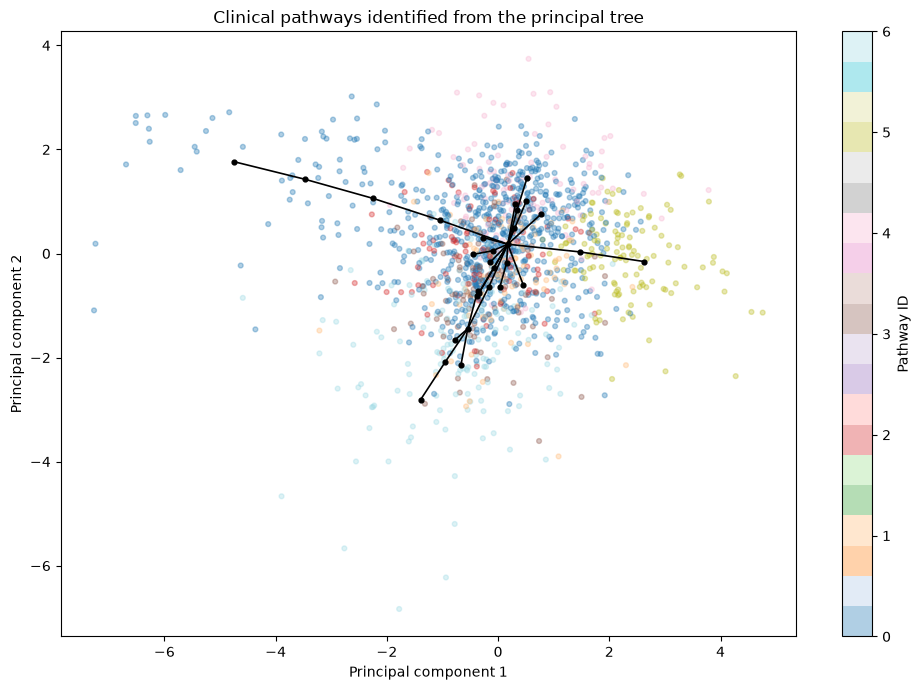

In [59]:
# Visualize pathway assignments in the first two PCA dimensions.
fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    P_train[:, 0],
    P_train[:, 1],
    c=train_pathway.to_numpy(),
    cmap="tab20",
    s=12,
    alpha=0.35
)

for a, b in edges:
    ax.plot(
        nodes[[a, b], 0],
        nodes[[a, b], 1],
        color="black",
        linewidth=1.2
    )

ax.scatter(
    nodes[:, 0],
    nodes[:, 1],
    s=12,
    color="black"
)

ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title("Clinical pathways identified from the principal tree")

colorbar = fig.colorbar(scatter, ax=ax)
colorbar.set_label("Pathway ID")

plt.tight_layout()
plt.show()

## 7.4 Complication profiles across clinical pathways

The reconstructed pathways are evaluated using the independent
test cohort.

For each pathway, the prevalence of all eleven post-MI
complications is calculated.

Permutation tests examine whether complication frequencies
differ across pathways. Benjamini–Hochberg correction is
applied to account for multiple testing.

Small pathways and rare complications are interpreted
cautiously because their prevalence estimates may be unstable.

This analysis investigates associations, not causal effects
or prospective prediction of complications.

,Test patients
Pathway,
0,176
1,19
2,19
3,25
4,27
5,38
6,36


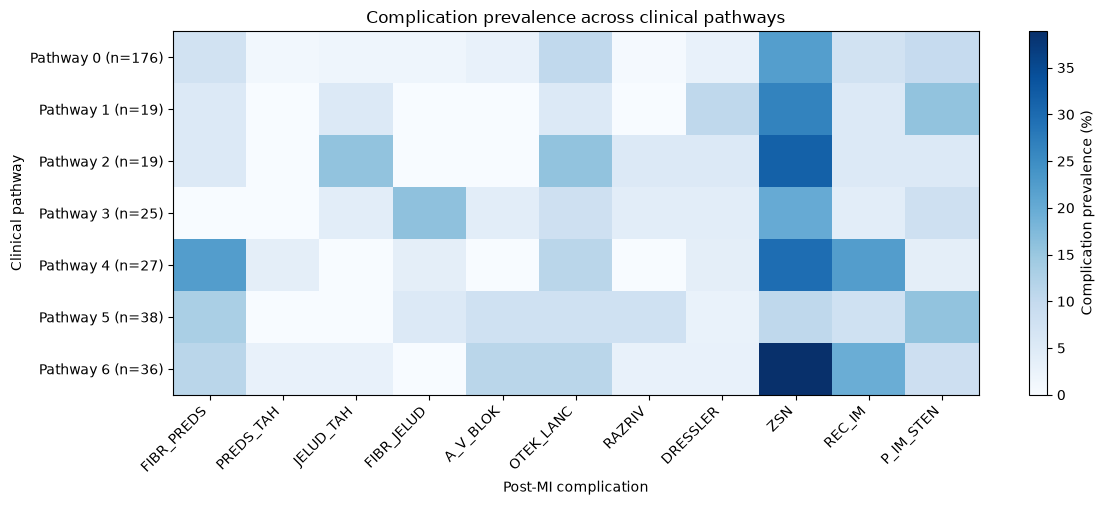

,Complication,Test events,Permutation p,Adjusted p
2,JELUD_TAH,9,0.023,0.126
3,FIBR_JELUD,10,0.011,0.126
0,FIBR_PREDS,30,0.100,0.204
4,A_V_BLOK,13,0.111,0.204
6,RAZRIV,7,0.087,0.204
9,REC_IM,32,0.072,0.204
8,ZSN,81,0.137,0.216
1,PREDS_TAH,4,0.810,0.891
7,DRESSLER,12,0.780,0.891
10,P_IM_STEN,33,0.672,0.891


In [60]:
# Outcome data for the test patients.
pathway_outcomes = Y_test.loc[
    X7_test.index, outcomes
].copy()

pathway_outcomes["Pathway"] = test_pathway

# Show test-cohort pathway sizes.
pathway_sizes = (
    pathway_outcomes["Pathway"]
    .value_counts()
    .sort_index()
)

display(
    pathway_sizes.rename("Test patients").to_frame()
)

# Prevalence of each complication within each pathway.
pathway_rates = (
    pathway_outcomes
    .groupby("Pathway")[outcomes]
    .mean() * 100
)

fig, ax = plt.subplots(
    figsize=(12, max(4, 0.45 * len(pathway_rates) + 2))
)

im = ax.imshow(
    pathway_rates.to_numpy(),
    aspect="auto",
    cmap="Blues",
    vmin=0
)

ax.set_xticks(range(len(outcomes)))
ax.set_xticklabels(outcomes, rotation=45, ha="right")

ax.set_yticks(range(len(pathway_rates)))
ax.set_yticklabels([
    f"Pathway {i} (n={pathway_sizes.loc[i]})"
    for i in pathway_rates.index
])

ax.set_title("Complication prevalence across clinical pathways")
ax.set_xlabel("Post-MI complication")
ax.set_ylabel("Clinical pathway")

fig.colorbar(
    im, ax=ax, label="Complication prevalence (%)"
)

plt.tight_layout()
plt.show()

# Permutation tests: one global association test per outcome.
rng = np.random.default_rng(42)

labels = test_pathway.to_numpy()
test_results = []

for outcome in outcomes:
    y = pathway_outcomes[outcome].to_numpy()

    # Exclude missing outcome labels, if any.
    valid = pd.notna(y)
    y_valid = y[valid].astype(int)
    labels_valid = labels[valid]

    if len(np.unique(y_valid)) < 2:
        p_value = np.nan

    else:
        observed_table = pd.crosstab(
            labels_valid, y_valid
        ).reindex(columns=[0, 1], fill_value=0)

        observed_stat = chi2_contingency(
            observed_table,
            correction=False
        )[0]

        extreme = 0
        n_permutations = 2000

        for _ in range(n_permutations):
            shuffled = rng.permutation(y_valid)

            table = pd.crosstab(
                labels_valid, shuffled
            ).reindex(columns=[0, 1], fill_value=0)

            statistic = chi2_contingency(
                table,
                correction=False
            )[0]

            extreme += statistic >= observed_stat

        p_value = (extreme + 1) / (n_permutations + 1)

    test_results.append({
        "Complication": outcome,
        "Test events": int(np.nansum(y_valid)),
        "Permutation p": p_value
    })

pathway_associations = pd.DataFrame(test_results)

valid = pathway_associations["Permutation p"].notna()

pathway_associations.loc[valid, "Adjusted p"] = (
    multipletests(
        pathway_associations.loc[valid, "Permutation p"],
        method="fdr_bh"
    )[1]
)

display(
    pathway_associations
    .sort_values("Adjusted p")
    .round(3)
)

## 7.5 Conclusion

- **Elastic principal tree:**
  - Constructed using 1,360 training patients and clinical information available by 72 hours.
  - The tree contains 30 nodes and 29 edges.
  - Two branching points indicate where the clinical structure splits into different directions.
  - These branches reflect differences in patient characteristics, not necessarily disease progression.

- **Seven clinical pathways:**
  - The tree was divided into seven pathways based on its structure.
  - Pathway 0 is the largest, containing 705 training patients.
  - In the colored PCA figure, each color represents patients assigned to a different pathway.
  - The overlap between colors suggests that some patient profiles are similar.

- **Complication heatmap:**
  - Shows the prevalence of all 11 complications across the seven pathways.
  - Darker blue indicates a higher percentage of patients experiencing a complication.
  - Some pathways show higher complication rates than others.

- **Statistical testing:**
  - Permutation tests were performed using 340 independent test patients.
  - Benjamini–Hochberg correction accounts for testing 11 complications.
  - None of the associations remained statistically significant (all adjusted p-values > 0.05).
  - Therefore, the observed differences may reflect random variation.

- **Overall conclusion:**
  - The elastic principal tree identified different clinical patient profiles, but their association with complications was not statistically confirmed.
  - The approach is inspired by Golovenkin et al. (2020), although the pathways represent inferred clinical similarities rather than observed trajectories over time.